# Notebook 01 — Entender os dados (coleta intercalada NOVOS_2.0)

**O que buscamos aqui:** olhar os dados com calma, antes de qualquer modelo. Queremos responder cinco perguntas simples:

1. Os dados estão no formato esperado (unidade, eixos, gravidade)?
2. Cada base está estável, ou seja, tem uma só velocidade e nenhuma troca no meio?
3. O que muda no sinal entre as velocidades e entre normal e anomalia?
4. Em quais frequências a vibração aparece?
5. **(novo)** Os 5 lotes de normal, gravados entre as anomalias, são iguais entre si? O que muda ao longo da sessão?

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar parâmetros | Um único lugar para ajustar caminhos, opções e a ordem da sessão |
| 2 | (Opcional) Cortar um arquivo com várias velocidades | Uma base por velocidade e por condição |
| 3 | Carregar as bases | Cada arquivo vira uma base com condição, velocidade, lote e posição na sessão |
| 4 | Conferir os dados | Unidade correta, sem valores faltando, gravidade no eixo esperado |
| 5 | Olhar 1 segundo de sinal | Enxergar a vibração e comparar as bases na mesma escala |
| 6 | Desvio padrão segundo a segundo | Confirmar que a base é estável |
| 7 | Features no tempo (desvio padrão, curtose e pico) | Ver quais bases já se separam só com o domínio do tempo |
| 8 | FFT com janela de Hanning | Ver em quais frequências a vibração aparece |
| 9 | Espectrograma | Ver como as frequências se comportam ao longo do tempo |
| 10 | **A sessão intercalada** | Comparar os lotes de normal e ver a rotação e a inclinação de cada gravação, na ordem em que foram gravadas |

## Como usar

1. Coloque os CSVs numa pasta, **um arquivo por base**, com o nome `<condicao>_vel_<N>.csv`. Exemplos: `fita_1g_vel_2.csv` e `calco_vel_1.csv`. Quando a mesma condição foi gravada várias vezes (os lotes de normal), acrescente `_lote_<K>` no fim: `ventilador_normal_vel_1_lote_3.csv`.
2. Cada CSV tem as colunas `x`, `y` e `z`, em m/s², amostradas a 1 kHz, com **uma condição e uma velocidade por arquivo**.
3. Ajuste o Passo 1 (o caminho da pasta e a ordem da sessão) e rode as células de cima para baixo.

**Atenção:** se o seu arquivo tem várias velocidades na mesma gravação (como os dados antigos, de ~30 minutos), faça primeiro o Passo 2 para cortá-lo. Os demais passos assumem uma velocidade por base.

## Sobre os dados desta versão (NOVOS_2.0)

Esta é a versão do Notebook 01 para a **coleta intercalada** (pasta `NOVOS_DADOS/NOVOS_2.0`), gravada para atender ao pedido do orientador de terminar os testes intercalados:

* **Ventilador Mondial VSP30B com a oscilação ligada**, como nas coletas anteriores.
* **27 bases de cerca de 3 minutos:** 5 lotes de `ventilador_normal` e 4 anomalias, cada uma nas 3 velocidades. As anomalias são `calco` (calço sob um pé), `fita_05g` e `fita_1g` (fita com massa de 0,5 g e de 1 g na hélice) e `papel` (folha que bate na hélice). **Não há porca frouxa nesta coleta.**
* **Protocolo intercalado:** normal, anomalia, normal, anomalia, e assim até o fim (N1, anomalia, N2, anomalia, N3, anomalia, N4, anomalia, N5). Antes de cada bloco o ventilador era ligado, esperava-se 1 minuto e gravava-se 3 minutos na Vel 1; depois a velocidade era trocada para 2 e para 3, **sem desligar**. O ventilador ficava desligado até a próxima falha ser instalada ou a anterior ser retirada.
* **Diferença para a coleta anterior:** lá, cada gravação (cerca de 10 min) começava com o motor frio, depois de cerca de 1 h de espera. Aqui **não há espera para esfriar**, então o motor esquenta ao longo da sessão e os lotes de normal podem não ser iguais.
* **Ordem entre as fitas não anotada:** foi assumida a ordem `calco`, `fita_1g`, `fita_05g`, `papel`, que só afeta a posição das gravações nos gráficos do Passo 10 e nos números de ordem do catálogo.
* **Frequências de 120 e 240 Hz:** o orientador confirmou que são **componente elétrica** (o 240 Hz é harmônico do 120 Hz). Elas aparecem marcadas nos gráficos de espectro.
* Os notebooks das versões anteriores continuam nas pastas `DADOS_NOVOS` e `NOTEBOOKS_REPLICAVEIS`, como registro.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** concentrar tudo o que muda de um experimento para outro num só lugar. Para reaplicar o notebook em dados novos, basta mexer na célula de parâmetros.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import signal
from scipy.stats import kurtosis
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS
# Pasta com UM CSV por base (pode estar em subpastas). Nome do arquivo = <condicao>_vel_<N>.csv
# (os lotes repetidos levam _lote_<K> no fim, por exemplo ventilador_normal_vel_1_lote_3.csv)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS\NOVOS_2.0")
BUSCAR_EM_SUBPASTAS = True   # True = lê também os CSVs dentro das subpastas (NORMAL_LOTE_1, CALCO, ...)

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000     # amostras por segundo (ESP32 + MPU6050)
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"              # unidade dos valores nos CSVs

# ----------------------------------------------------------------------
# ORDEM DA SESSÃO (coleta intercalada: normal, anomalia, normal, anomalia, ...)
# Um item por bloco, na ordem em que foram gravados. Em cada bloco as velocidades foram gravadas 1, 2 e 3.
# ATENÇÃO: a ordem entre fita_1g e fita_05g NÃO foi anotada; aqui está assumida (1 g antes de 0,5 g).
# Se a ordem real for outra, só trocar as duas posições. Use None se a coleta não for intercalada.
# ----------------------------------------------------------------------
ORDEM_SESSAO = [
    "ventilador_normal", "calco", "ventilador_normal", "fita_1g", "ventilador_normal",
    "fita_05g", "ventilador_normal", "papel", "ventilador_normal",
]

# ----------------------------------------------------------------------
# LIMPEZA DO COMEÇO E DO FIM DE CADA GRAVAÇÃO (Passo 4.1)
# ----------------------------------------------------------------------
DESCARTAR_INICIO_S = 5        # segundos descartados no começo de cada base (falhas de leitura ao ligar a gravação)
DESCARTAR_FIM_S = 5           # segundos descartados no fim de cada base (manuseio ao parar a gravação)
LIMITE_CURTOSE_SUSPEITA = 8   # janela com curtose acima disto, em algum eixo, é marcada como suspeita

# ----------------------------------------------------------------------
# PARÂMETROS DA ANÁLISE
# ----------------------------------------------------------------------
JANELA_S = 5                  # janela (s) das features e da FFT, sem sobreposição
F_MIN_HZ = 5                  # a FFT ignora frequências abaixo disto (deriva lenta do sensor)
F_MAX_HZ = 300                # limite superior dos gráficos de frequência
INICIO_TRECHO_S = None        # onde começa o trecho de 1 s dos gráficos (None = meio de cada base)
INICIO_FFT_S = 0              # segundo da base em que começa a janela usada nos gráficos de FFT
BASE_EXEMPLO = None           # base dos gráficos com uma única base (None = a primeira)
EIXO_ESPECTROGRAMA = "x"      # eixo usado no espectrograma
FAIXA_BUSCA_1X_HZ = (8, 30)   # onde procurar a rotação (1X) no Passo 10
DESVIO_MAX_1X_HZ = 2.0        # na 2ª passada, o 1X de cada janela fica a até isto da rotação típica da base

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_EIXOS = {"x": "red", "y": "green", "z": "blue"}
NOMES_EIXOS = {"x": "Eixo X (lateral)", "y": "Eixo Y (frontal)", "z": "Eixo Z (vertical)"}
CORES_VELOCIDADE = {1: "dodgerblue", 2: "crimson", 3: "limegreen"}
CONDICAO_NORMAL = "ventilador_normal"   # condição de referência, usada para montar os grupos do Passo 7.2
MARCADORES_CONDICAO = ["o", "^", "s", "D", "v"]

## Passo 2 (opcional) — Cortar um arquivo que tem várias velocidades

**O que buscamos:** transformar uma gravação longa, com as velocidades em sequência, em **uma base por velocidade**, cada uma num CSV com nome rotulado. Isto é feito **uma vez**. Depois, o notebook só lê a pasta de bases.

**Quando usar:** só se o seu arquivo tem mais de uma velocidade (caso dos dados antigos). **Os dados novos já vêm separados por velocidade: nesta versão, pule este passo.** As células de corte estão comentadas de propósito: se rodadas por engano, poderiam sobrescrever arquivos da pasta de bases.

**Como usar** (as duas células de execução abaixo estão comentadas):

1. Descomente a primeira célula (selecione todas as linhas e use `Ctrl + /`), ajuste o caminho e o prefixo do nome e rode. Ela mostra o desvio padrão segundo a segundo.
2. Nesse gráfico, os **degraus** são as trocas de velocidade. Anote o segundo de cada troca e deixe uma margem de segurança, para descartar o acionamento manual dos botões.
3. Descomente a segunda célula, preencha os cortes `{velocidade: (início_s, fim_s)}` e rode. Ela salva um CSV por velocidade em `PASTA_BASES`. A função **não sobrescreve** arquivos que já existem.
4. Comente as duas células de volta.

Cortes dos dados antigos, validados nos notebooks de ML (em segundos):

| Arquivo | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Normal | 20 a 620 | 660 a 1230 | 1270 a 1780 |
| Fita | 20 a 580 | 620 a 1170 | 1210 a 1800 |

In [3]:
def calcular_std_por_segundo(df):
    """Desvio padrão de cada eixo em cada segundo inteiro da base.

    O desvio padrão ignora a gravidade (valor constante) e mede só a intensidade
    da trepidação. O último segundo incompleto é descartado.
    """
    n_segundos = len(df) // TAXA_AMOSTRAGEM_HZ
    df = df[EIXOS].iloc[: n_segundos * TAXA_AMOSTRAGEM_HZ]
    segundo = np.arange(len(df)) // TAXA_AMOSTRAGEM_HZ
    return df.groupby(segundo).std()


def plotar_std_por_segundo(std_por_base, catalogo=None):
    """O desvio padrão de X, Y e Z ao longo do tempo, uma base por gráfico.

    std_por_base: dicionário {nome da base: saída de calcular_std_por_segundo}.
    Sem catalogo: uma linha de gráficos por base. Com catalogo: uma grade (bloco da sessão x velocidade),
    que é o formato certo para muitas bases.
    """
    if catalogo is None:
        fig, axs = plt.subplots(len(std_por_base), 1, figsize=(15, 3.2 * len(std_por_base)), squeeze=False)
        celulas = list(zip(axs[:, 0], std_por_base.keys()))
        axs[-1, 0].set_xlabel("Tempo (s)")
    else:
        fig, axs, celulas = criar_grade(catalogo, largura=6, altura=2.6, sharex=True, sharey=False,
                                        rotulo_x="Tempo (s)", rotulo_y=f"Desvio padrão ({UNIDADE})")
    for ax, nome in celulas:
        std_seg = std_por_base[nome]
        for eixo in EIXOS:
            ax.plot(std_seg.index, std_seg[eixo], color=CORES_EIXOS[eixo], linewidth=1.2, label=NOMES_EIXOS[eixo])
        if catalogo is None:
            ax.set_title(nome, fontsize=12, fontweight="bold")
            ax.set_ylabel(f"Desvio padrão ({UNIDADE})")
        ax.xaxis.set_major_locator(MaxNLocator(nbins=10 if catalogo is not None else 15, integer=True))
    manipulos, nomes = celulas[0][0].get_legend_handles_labels()
    fig.legend(manipulos, nomes, loc="upper center", ncol=3, fontsize=10, frameon=False)
    plt.tight_layout(rect=[0, 0, 1, 0.975])
    plt.show()


def salvar_bases_recortadas(df_longo, cortes, prefixo_nome, pasta_saida, sobrescrever=False):
    """Corta o arquivo longo e salva um CSV por velocidade: <prefixo_nome>_vel_<N>.csv.

    cortes: dicionário {velocidade: (inicio_s, fim_s)}.
    """
    pasta_saida = Path(pasta_saida)
    pasta_saida.mkdir(parents=True, exist_ok=True)
    for velocidade, (inicio_s, fim_s) in cortes.items():
        destino = pasta_saida / f"{prefixo_nome}_vel_{velocidade}.csv"
        if destino.exists() and not sobrescrever:
            raise FileExistsError(f"{destino.name} já existe. Use sobrescrever=True se for de propósito.")
        trecho = df_longo[EIXOS].iloc[int(inicio_s * TAXA_AMOSTRAGEM_HZ): int(fim_s * TAXA_AMOSTRAGEM_HZ)]
        trecho.to_csv(destino, index=False)
        print(f"Salvo: {destino.name} ({len(trecho)} linhas = {len(trecho) / TAXA_AMOSTRAGEM_HZ:.0f} s)")

In [4]:
# ARQUIVO_LONGO = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\DADOS_NORMAIS_1KHZ\dados_valores_xyz_puro.csv")
# PREFIXO_NOME = "ventilador_normal"

# df_longo = pd.read_csv(ARQUIVO_LONGO)
# plotar_std_por_segundo({PREFIXO_NOME: calcular_std_por_segundo(df_longo)})

In [5]:
# ARQUIVO_LONGO = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\DADOS_FITA_1KHZ\dados_valores_xyz_puro_fita.csv")
# PREFIXO_NOME = "fita_1g"

# df_longo = pd.read_csv(ARQUIVO_LONGO)
# plotar_std_por_segundo({PREFIXO_NOME: calcular_std_por_segundo(df_longo)})

In [6]:
# CORTES = {
#      1: (20, 620),
#      2: (660, 1230),
#      3: (1270, 1780),
# }
# salvar_bases_recortadas(df_longo, CORTES, PREFIXO_NOME, PASTA_BASES, sobrescrever=True)

In [7]:
# CORTES = {
#     1: (20, 580),
#     2: (620, 1170),
#     3: (1210, 1800),
# }
# salvar_bases_recortadas(df_longo, CORTES, PREFIXO_NOME, PASTA_BASES)

## Passo 3 — Carregar as bases

**O que buscamos:** ler todos os CSVs da pasta e guardar, para cada base, o **nome**, a **condição** (ex.: `fita_1g`), a **velocidade** (ex.: `2`) e o **lote** (os 5 normais), que vêm do nome do arquivo. O nome do arquivo é o gabarito, então ele precisa seguir o padrão `<condicao>_vel_<N>` (mais `_lote_<K>` quando a condição foi gravada várias vezes).

O resultado são dois objetos:

* `bases`: dicionário `{nome da base: tabela com x, y e z}`.
* `catalogo`: tabela-resumo com uma linha por base: condição, velocidade, lote, número de linhas e duração, e quatro colunas que descrevem **onde a gravação ficou na sessão intercalada**: `posicao_sessao` (1 a 9, o bloco), `ordem_gravacao` (1 a 27, contando as velocidades 1, 2 e 3 dentro de cada bloco), `bloco_curto` (N1 a N5 para os normais) e `grupo` (o nome do bloco nos gráficos).

Também definimos aqui a função que monta os gráficos em **grade**, com **uma linha por bloco da sessão** (na ordem em que foram gravados) e uma coluna por velocidade. Assim, cada anomalia fica entre os dois normais que vieram antes e depois dela.

In [8]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)(?:_lote_(?P<lote>\d+))?$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome em condição, velocidade e lote.

    'fita_1g_vel_2' -> ('fita_1g', 2, 0);  'ventilador_normal_vel_1_lote_3' -> ('ventilador_normal', 1, 3).
    Lote 0 quer dizer que a condição foi gravada uma vez só.
    """
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2' "
            f"(ou <condicao>_vel_<N>_lote_<K>, por exemplo 'ventilador_normal_vel_1_lote_3')."
        )
    return encontrado["condicao"], int(encontrado["velocidade"]), int(encontrado["lote"] or 0)


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição, lote e velocidade."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(
            f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES ou, se o arquivo tem várias velocidades, faça o Passo 2."
        )
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade, lote = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "lote": lote,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "lote", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo


def adicionar_posicao_na_sessao(catalogo, ordem_sessao=ORDEM_SESSAO, condicao_normal=CONDICAO_NORMAL):
    """Acrescenta ao catálogo onde cada gravação ficou na sessão intercalada e reordena o catálogo por ela.

    Colunas novas: posicao_sessao (o bloco, 1 a 9), ordem_gravacao (1 a 27: 3 velocidades por bloco, na ordem 1, 2, 3),
    bloco_curto (N1 a N5 para os normais; o nome da condição para as anomalias) e grupo (o texto dos gráficos).
    Os lotes do normal recebem as posições na ordem em que aparecem em ordem_sessao.
    Com ordem_sessao=None, a ordem é a alfabética e cada condição/lote vira um bloco.
    """
    catalogo = catalogo.copy()
    if ordem_sessao is None:
        blocos = sorted(set(zip(catalogo["condicao"], catalogo["lote"])))
        posicao = {bloco: i for i, bloco in enumerate(blocos, start=1)}
    else:
        posicao, lote_atual = {}, 0
        for i, condicao in enumerate(ordem_sessao, start=1):
            if condicao == condicao_normal:
                lote_atual += 1
                posicao[(condicao, lote_atual)] = i
            else:
                posicao[(condicao, 0)] = i
        sem_posicao = sorted(set(zip(catalogo["condicao"], catalogo["lote"])) - set(posicao))
        if sem_posicao:
            raise ValueError(f"Estas condições/lotes não estão em ORDEM_SESSAO: {sem_posicao}. Ajuste o Passo 1.")
    catalogo["posicao_sessao"] = [posicao[(c, l)] for c, l in zip(catalogo["condicao"], catalogo["lote"])]
    n_velocidades = catalogo["velocidade"].nunique()
    catalogo["ordem_gravacao"] = (catalogo["posicao_sessao"] - 1) * n_velocidades + catalogo["velocidade"]
    eh_normal = catalogo["condicao"] == condicao_normal
    catalogo["bloco_curto"] = np.where(eh_normal, "N" + catalogo["lote"].astype(str), catalogo["condicao"])
    catalogo["grupo"] = [
        f"{p}. normal (lote {l})" if normal else f"{p}. {c}"
        for p, l, c, normal in zip(catalogo["posicao_sessao"], catalogo["lote"], catalogo["condicao"], eh_normal)
    ]
    catalogo["rotulo"] = catalogo["bloco_curto"] + " V" + catalogo["velocidade"].astype(str)
    return catalogo.sort_values(["posicao_sessao", "velocidade"])


def criar_grade(catalogo, largura=6, altura=3.2, sharex=True, sharey=True, rotulo_x=None, rotulo_y=None):
    """Cria uma grade de gráficos: uma linha por bloco da sessão e uma coluna por velocidade.

    As linhas seguem a ordem em que as gravações foram feitas (coluna 'grupo' do catálogo, ou 'condicao'
    se o catálogo não tiver posição na sessão). rotulo_x vai embaixo de cada coluna e rotulo_y à esquerda de cada linha.
    Devolve (figura, eixos, celulas), onde celulas é a lista [(eixo do gráfico, nome da base), ...]
    só com as combinações que existem. As combinações sem base ficam ocultas.
    """
    coluna_linha = "grupo" if "grupo" in catalogo.columns else "condicao"
    ordem = catalogo.sort_values(["posicao_sessao"]) if "posicao_sessao" in catalogo.columns else catalogo.sort_values(coluna_linha)
    linhas_da_grade = list(dict.fromkeys(ordem[coluna_linha]))
    velocidades = sorted(catalogo["velocidade"].unique())
    nome_por_celula = {(linha[coluna_linha], linha.velocidade): nome for nome, linha in catalogo.iterrows()}

    fig, axs = plt.subplots(
        len(linhas_da_grade), len(velocidades),
        figsize=(largura * len(velocidades), altura * len(linhas_da_grade)),
        sharex=sharex, sharey=sharey, squeeze=False,
    )
    celulas = []
    for i, linha_da_grade in enumerate(linhas_da_grade):
        for j, velocidade in enumerate(velocidades):
            nome = nome_por_celula.get((linha_da_grade, velocidade))
            if nome is None:
                axs[i, j].set_visible(False)
                continue
            axs[i, j].set_title(f"{linha_da_grade} — Vel {velocidade}", fontsize=11, fontweight="bold")
            celulas.append((axs[i, j], nome))
            # rótulo do eixo x só na última célula visível de cada coluna
            ultima_linha = max(k for k, c in enumerate(linhas_da_grade) if (c, velocidade) in nome_por_celula)
            if rotulo_x and i == ultima_linha:
                axs[i, j].set_xlabel(rotulo_x)
            if rotulo_y and j == 0:
                axs[i, j].set_ylabel(rotulo_y)
    return fig, axs, celulas

In [9]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
catalogo = adicionar_posicao_na_sessao(catalogo)
bases = {nome: bases[nome] for nome in catalogo.index}      # as bases passam a seguir a ordem da sessão
display(catalogo)

,condicao,velocidade,lote,linhas,duracao_s,posicao_sessao,ordem_gravacao,bloco_curto,grupo,rotulo
base,,,,,,,,,,
ventilador_normal_vel_1_lote_1,ventilador_normal,1,1,181500,181.5,1,1,N1,1. normal (lote 1),N1 V1
ventilador_normal_vel_2_lote_1,ventilador_normal,2,1,186000,186.0,1,2,N1,1. normal (lote 1),N1 V2
ventilador_normal_vel_3_lote_1,ventilador_normal,3,1,191000,191.0,1,3,N1,1. normal (lote 1),N1 V3
calco_vel_1,calco,1,0,189000,189.0,2,4,calco,2. calco,calco V1
calco_vel_2,calco,2,0,195000,195.0,2,5,calco,2. calco,calco V2
calco_vel_3,calco,3,0,228500,228.5,2,6,calco,2. calco,calco V3
ventilador_normal_vel_1_lote_2,ventilador_normal,1,2,203500,203.5,3,7,N2,3. normal (lote 2),N2 V1
ventilador_normal_vel_2_lote_2,ventilador_normal,2,2,191000,191.0,3,8,N2,3. normal (lote 2),N2 V2
ventilador_normal_vel_3_lote_2,ventilador_normal,3,2,188000,188.0,3,9,N2,3. normal (lote 2),N2 V3


In [10]:
CONDICOES_USADAS = None   # exemplo: ["ventilador_normal"]. None = usa todas
if CONDICOES_USADAS is not None:
    catalogo = catalogo[catalogo["condicao"].isin(CONDICOES_USADAS)]
    bases = {nome: bases[nome] for nome in catalogo.index}

## Passo 4 — Conferir os dados

**O que buscamos:** garantir que os dados fazem sentido antes de analisar. Olhamos três coisas:

* **Valores faltando** (`nan`): devem ser zero.
* **Unidade:** o eixo Z mede a gravidade. Em m/s² ele fica perto de 9,8 (nos dados anteriores, ~10,6 a 10,8, por causa do offset do sensor). Se ficasse perto de 1, os dados estariam em g.
* **Orientação do sensor:** os eixos X e Y devem ficar perto de 0, pois são perpendiculares à gravidade. Se o Z não for o eixo da gravidade, a montagem do sensor mudou e os nomes "lateral, frontal e vertical" deixam de valer.

In [11]:
def resumir_bases(bases):
    """Tabela com valores faltando, média e desvio padrão de cada eixo, por base."""
    linhas = []
    for nome, df in bases.items():
        linha = {"base": nome, "nan": int(df.isna().sum().sum())}
        for eixo in EIXOS:
            linha[f"media_{eixo}"] = df[eixo].mean()
        for eixo in EIXOS:
            linha[f"std_{eixo}"] = df[eixo].std()
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("base")

In [12]:
resumo = resumir_bases(bases)
display(resumo.round(3))

,nan,media_x,media_y,media_z,std_x,std_y,std_z
base,,,,,,,
ventilador_normal_vel_1_lote_1,0,-0.551,-0.362,10.709,0.677,0.809,0.247
ventilador_normal_vel_2_lote_1,0,-0.586,-0.334,10.702,2.167,1.313,0.617
ventilador_normal_vel_3_lote_1,0,-0.618,-0.294,10.702,1.098,0.749,0.414
calco_vel_1,0,-1.273,-0.794,10.540,0.814,1.030,0.270
calco_vel_2,0,-1.267,-0.761,10.555,2.188,1.561,0.661
calco_vel_3,0,-1.262,-0.729,10.549,1.287,1.072,0.649
ventilador_normal_vel_1_lote_2,0,-0.538,-0.370,10.706,0.695,0.766,0.251
ventilador_normal_vel_2_lote_2,0,-0.545,-0.354,10.712,2.538,1.526,0.686
ventilador_normal_vel_3_lote_2,0,-0.563,-0.313,10.709,1.082,0.746,0.428


### Conclusões do Passo 4 (nesta execução, NOVOS_2.0)

* **27 bases, de 179 a 228,5 s cada** (antes do corte do Passo 4.2), todas com número de linhas múltiplo de 500 (pacotes completos). **Nenhum valor faltando.**
* **Unidade e orientação iguais às das coletas anteriores:** o eixo Z fica em 10,54 a 10,73 m/s² (gravidade com o offset do sensor), e X e Y ficam perto de zero (X de −1,27 a −0,46 e Y de −0,79 a −0,24).
* **O calço inclinou o ventilador.** Nas 3 velocidades do calço, a média de X é −1,27 e a de Y é −0,79 a −0,73, contra −0,62 a −0,47 (X) e −0,39 a −0,28 (Y) nos 5 lotes de normal. A diferença (cerca de 0,75 em X e 0,42 em Y) corresponde a algo da ordem de **5° de inclinação** (0,17 m/s² vale cerca de 1°). Nas outras três anomalias a média fica a menos de 0,07 m/s² da média dos normais.
* **Isso não afeta as features**, que são calculadas depois de remover a média de cada janela. Mas é uma diferença real entre o calço e o normal que o modelo não vê. O Passo 10.3 detalha.
* **A média de X dos normais sobe de forma contínua ao longo da sessão** (na Vel 1: −0,56, −0,53, −0,51, −0,48 e −0,47 de N1 a N5). É uma deriva pequena (cerca de 0,1 m/s², menos de 1°), que pode ser a temperatura do sensor ou o ventilador assentando. Também é tratada no Passo 10.3.

### 4.1 — Picos isolados no começo e no fim das gravações

**O que buscamos:** encontrar trechos com **falhas de leitura do sensor** ou **manuseio**, que não são vibração do ventilador. Uma falha típica é **uma única amostra absurda**: por exemplo, 87 m/s² no meio de valores perto de 0, ou um 0 no meio de valores perto de 10,7. Ela é rápida demais para ser vibração real.

**Como encontramos:** pela **curtose** de cada janela de `JANELA_S` segundos. A curtose mede o quanto um sinal tem picos raros e fortes. Uma vibração comum fica entre −1 e 3; **uma única amostra absurda faz a curtose da janela ir a centenas ou milhares**. A tabela lista as janelas com curtose acima de `LIMITE_CURTOSE_SUSPEITA` em algum eixo, com a **posição da janela** na gravação (janela 0 = primeiros 5 s).

**O que procurar:** se as janelas suspeitas se concentram **no começo ou no fim** das gravações, a causa é ligar e desligar a gravação, e basta descartar esses trechos. Se aparecerem **no meio**, é preciso olhar caso a caso.

In [13]:
def encontrar_janelas_suspeitas(bases, janela_s=JANELA_S, limite=LIMITE_CURTOSE_SUSPEITA):
    """Janelas (sem sobreposição) com curtose acima do limite em algum eixo, com a posição na gravação."""
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    linhas = []
    for nome, df in bases.items():
        n_janelas = len(df) // tamanho
        dados = df[EIXOS].to_numpy()[: n_janelas * tamanho].reshape(n_janelas, tamanho, len(EIXOS))
        curtose = kurtosis(dados - dados.mean(axis=1, keepdims=True), axis=1, fisher=True)
        for janela in np.where((curtose > limite).any(axis=1))[0]:
            linha = {"base": nome, "janela": int(janela), "de": n_janelas - 1,
                     "trecho (s)": f"{janela * janela_s}–{(janela + 1) * janela_s}"}
            for k, eixo in enumerate(EIXOS):
                linha[f"curtose_{eixo}"] = round(float(curtose[janela, k]), 1)
            linhas.append(linha)
    return pd.DataFrame(linhas)

In [14]:
janelas_suspeitas = encontrar_janelas_suspeitas(bases)
if janelas_suspeitas.empty:
    print("Nenhuma janela suspeita.")
else:
    display(janelas_suspeitas)
    no_comeco = (janelas_suspeitas["janela"] == 0).sum()
    no_fim = (janelas_suspeitas["janela"] == janelas_suspeitas["de"]).sum()
    print(f"{len(janelas_suspeitas)} janelas suspeitas: {no_comeco} na primeira janela, {no_fim} na última, "
          f"{len(janelas_suspeitas) - no_comeco - no_fim} no meio.")

,base,janela,de,trecho (s),curtose_x,curtose_y,curtose_z
0,fita_05g_vel_3,36,38,180–185,1.2,3.0,11.2
1,fita_05g_vel_3,38,38,190–195,1.4,4.3,13.8


2 janelas suspeitas: 0 na primeira janela, 1 na última, 1 no meio.


### 4.2 — Descartar o começo e o fim de cada base

**O que fazemos:** cortamos `DESCARTAR_INICIO_S` segundos do começo e `DESCARTAR_FIM_S` do fim de **todas** as bases, mesmo das que não tiveram janela suspeita. Assim todas passam pelo mesmo tratamento e nenhuma condição fica com vantagem. **Todos os passos seguintes usam as bases já aparadas.**

**Por que só 5 s:** as falhas encontradas ficam todas dentro dos primeiros 3 s ou do último segundo. 5 s é a menor margem que cobre todas e é igual a uma janela. Se a tabela de conferência abaixo ainda mostrar janelas suspeitas, aumente os valores no Passo 1.

> **Os notebooks seguintes (02 em diante) aplicam o mesmo corte**, com os mesmos parâmetros, para que as features sejam calculadas exatamente sobre os mesmos trechos.

In [15]:
def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base. Devolve (bases, catalogo) atualizados."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo

In [16]:
bases, catalogo = aparar_bases(bases, catalogo)
print(f"Descartados {DESCARTAR_INICIO_S} s do começo e {DESCARTAR_FIM_S} s do fim de cada base.")
display(catalogo)

conferencia = encontrar_janelas_suspeitas(bases)
print("Janelas suspeitas depois do corte:", "nenhuma" if conferencia.empty else "")
if not conferencia.empty:
    display(conferencia)

Descartados 5 s do começo e 5 s do fim de cada base.


,condicao,velocidade,lote,linhas,duracao_s,posicao_sessao,ordem_gravacao,bloco_curto,grupo,rotulo
base,,,,,,,,,,
ventilador_normal_vel_1_lote_1,ventilador_normal,1,1,171500,171.5,1,1,N1,1. normal (lote 1),N1 V1
ventilador_normal_vel_2_lote_1,ventilador_normal,2,1,176000,176.0,1,2,N1,1. normal (lote 1),N1 V2
ventilador_normal_vel_3_lote_1,ventilador_normal,3,1,181000,181.0,1,3,N1,1. normal (lote 1),N1 V3
calco_vel_1,calco,1,0,179000,179.0,2,4,calco,2. calco,calco V1
calco_vel_2,calco,2,0,185000,185.0,2,5,calco,2. calco,calco V2
calco_vel_3,calco,3,0,218500,218.5,2,6,calco,2. calco,calco V3
ventilador_normal_vel_1_lote_2,ventilador_normal,1,2,193500,193.5,3,7,N2,3. normal (lote 2),N2 V1
ventilador_normal_vel_2_lote_2,ventilador_normal,2,2,181000,181.0,3,8,N2,3. normal (lote 2),N2 V2
ventilador_normal_vel_3_lote_2,ventilador_normal,3,2,178000,178.0,3,9,N2,3. normal (lote 2),N2 V3


Janelas suspeitas depois do corte: 


,base,janela,de,trecho (s),curtose_x,curtose_y,curtose_z
0,fita_05g_vel_3,35,36,175–180,1.2,3.0,11.2


### Conclusões dos Passos 4.1 e 4.2 (nesta execução)

* **2 janelas suspeitas, as duas na fita 0,5 g Vel 3** (180–185 s e 190–195 s), com curtose alta só no eixo Z (11,2 e 13,8). **Nenhuma é a primeira janela de uma gravação.** Uma é a última janela (que o corte descarta) e a outra fica no meio.
* **Não são falhas de leitura do sensor.** Olhando amostra por amostra, os valores vizinhos ao pico também são altos (25 a 30 m/s²), e o padrão se repete a cada cerca de 10 s (rajadas perto de 175, 185 e 194,5 s), que é o ciclo da oscilação na Vel 3. São **rajadas de vibração real**, que o Passo 6 mostra como picos regulares do desvio padrão do eixo Z. A janela do meio é **mantida**, como as atípicas reais dos notebooks anteriores.
* **Diferença para a coleta anterior:** lá, 8 das 9 janelas suspeitas eram a primeira janela da gravação (falhas de leitura ao ligar o sensor). Aqui **nenhuma** apareceu. Não sabemos o motivo (pode ser a espera de 1 min antes de gravar), e o corte de 5 s foi mantido igual, para que todas as bases passem pelo mesmo tratamento dos notebooks anteriores.
* **Depois do corte:** as bases ficam com 169 a 218,5 s, ou 33 a 43 janelas de 5 s, **1.000 janelas ao todo** (555 de normal e 445 de anomalia). São poucas janelas por gravação, o que pesa no desenho do teste trancado do Notebook 05.

## Passo 5 — Olhar 1 segundo de sinal

**O que buscamos:** enxergar a vibração em si. Mostramos 1 segundo (1000 amostras) de cada base, nos três eixos, com **a mesma escala vertical** em todos os gráficos, para comparar a espessura da faixa de vibração entre as bases.

* **5.1 — Sinal bruto:** o Z fica deslocado pela gravidade, o que confirma a orientação do sensor.
* **5.2 — Sem o componente DC:** subtraímos a média de cada eixo, o que remove a gravidade e centraliza tudo em zero. Fica só a vibração, e é assim que ela entra nas features e na FFT.

In [17]:
def escolher_inicio_do_trecho(df, duracao_s, inicio_s=None):
    """Segundo em que o trecho começa. Se inicio_s for None, usa o meio da base."""
    if inicio_s is not None:
        return inicio_s
    duracao_total_s = len(df) / TAXA_AMOSTRAGEM_HZ
    return max(0, int((duracao_total_s - duracao_s) / 2))


def extrair_trecho(df, inicio_s, duracao_s, remover_dc):
    """Recorta um trecho da base. Com remover_dc=True, subtrai a média de cada eixo."""
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    fim = inicio + int(duracao_s * TAXA_AMOSTRAGEM_HZ)
    trecho = df[EIXOS].iloc[inicio:fim]
    if remover_dc:
        trecho = trecho - trecho.mean()
    return trecho.reset_index(drop=True)


def plotar_trechos(bases, catalogo, duracao_s=1, inicio_s=None, remover_dc=False):
    """Grade (condição x velocidade) com um trecho de sinal de cada base, na mesma escala."""
    fig, axs, celulas = criar_grade(
        catalogo, sharex=True, sharey=True, rotulo_x="Tempo (s)", rotulo_y=f"Aceleração ({UNIDADE})"
    )
    for ax, nome in celulas:
        inicio = escolher_inicio_do_trecho(bases[nome], duracao_s, inicio_s)
        trecho = extrair_trecho(bases[nome], inicio, duracao_s, remover_dc)
        tempo = np.arange(len(trecho)) / TAXA_AMOSTRAGEM_HZ
        for eixo in EIXOS:
            ax.plot(tempo, trecho[eixo], color=CORES_EIXOS[eixo], linewidth=1, alpha=0.85, label=NOMES_EIXOS[eixo])
    axs[0, 0].legend(loc="upper right", fontsize=8)
    texto_dc = "sem o componente DC" if remover_dc else "sinal bruto (com gravidade)"
    fig.suptitle(f"{duracao_s} s de sinal — {texto_dc}", y=0.995, fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()

### 5.1 — Sinal bruto (com gravidade)

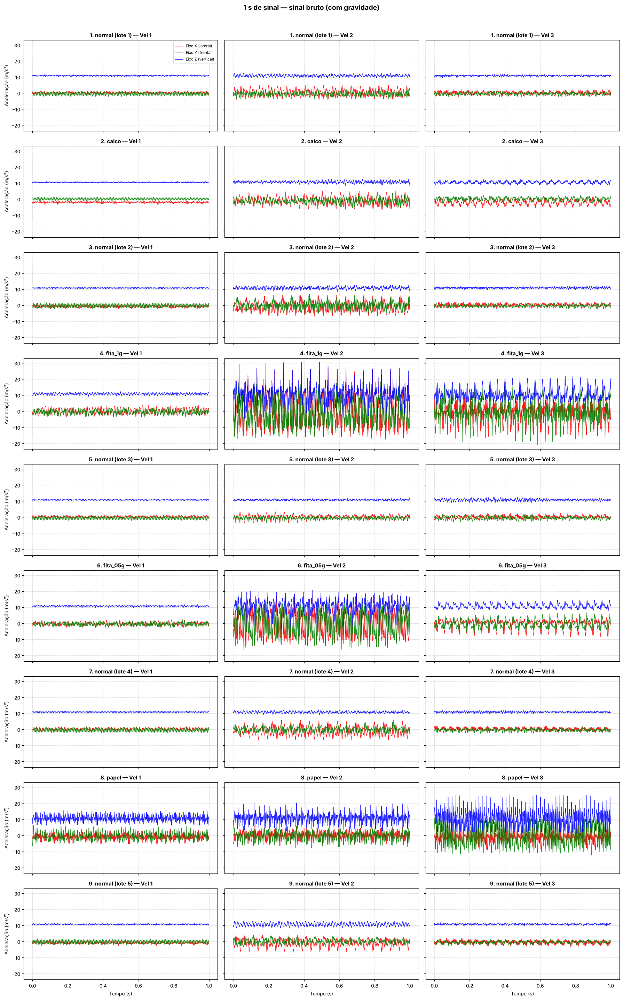

In [18]:
plotar_trechos(bases, catalogo, duracao_s=1, inicio_s=INICIO_TRECHO_S, remover_dc=False)

### 5.2 — Sem o componente DC (só a vibração)

Compare normal e anomalia na mesma velocidade (mesma coluna), e depois as velocidades entre si.

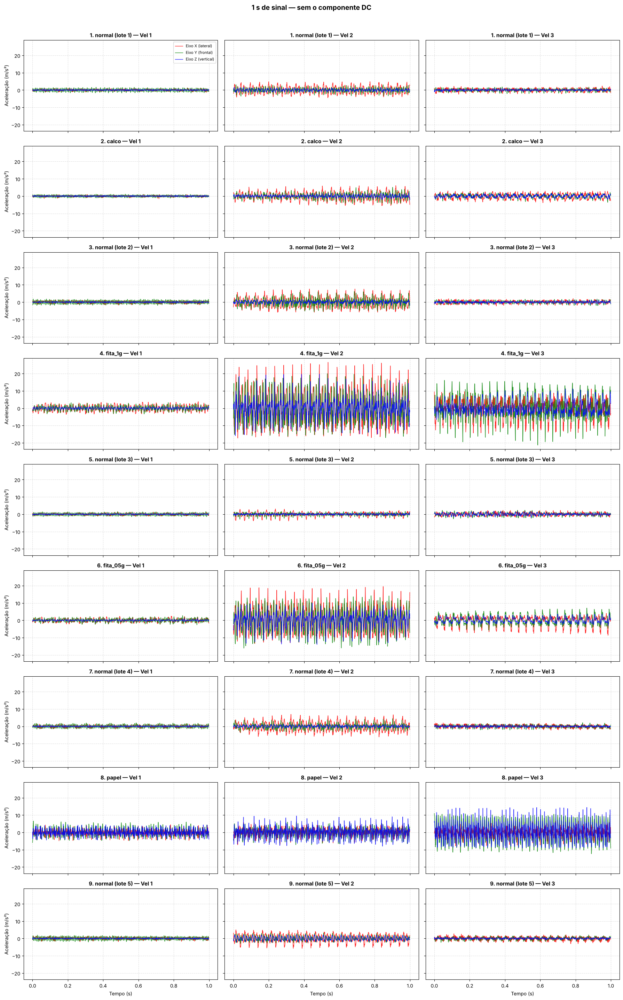

In [19]:
plotar_trechos(bases, catalogo, duracao_s=1, inicio_s=INICIO_TRECHO_S, remover_dc=True)

### Conclusões do Passo 5 (nesta execução)

**No sinal sem DC (5.2), a olho:**

* **A fita 1 g é a mais forte:** picos de cerca de ±25 m/s² na Vel 2 e ±20 na Vel 3, com impactos regulares. Na Vel 1 fica em ±3–4, perto do normal.
* **A fita 0,5 g tem o mesmo desenho, mais fraco:** ±15–20 na Vel 2, cerca de ±8 na Vel 3 (com picos negativos regulares no eixo X) e perto do normal na Vel 1.
* **O papel é a anomalia mais visível na Vel 1** (±5–8, sinal mais "denso") e a mais forte na Vel 3 (cerca de ±14 no eixo Z). Na Vel 2 fica em ±5–8.
* **O calço é parecido com o normal nas três velocidades.** A olho não dá para separá-lo.
* **Os 5 lotes de normal parecem iguais entre si** nesta escala (±1–2 na Vel 1, ±4–6 na Vel 2 e ±2 na Vel 3). As diferenças entre eles são pequenas e aparecem nos números dos próximos passos.

## Passo 6 — Desvio padrão segundo a segundo (a base é estável?)

**O que buscamos:** confirmar que cada base tem **um único regime**, ou seja, que o **patamar** do desvio padrão não muda ao longo da base. Calculamos o desvio padrão de cada segundo (as funções de cálculo e de gráfico foram definidas no Passo 2). Aqui os gráficos saem em **grade**, na ordem da sessão, e **cada gráfico tem a sua escala vertical**.

* **Oscilação regular em torno de um patamar:** em todas as coletas, as bases mostram uma oscilação periódica de alguns segundos. Ela **não** indica problema. O que importa é o nível médio.
* **Degrau (mudança de patamar) no meio da base:** houve troca de velocidade ou mudança no ensaio. A base precisa ser cortada de novo (Passo 2).
* **Picos isolados:** perturbação no teste, como um toque no ventilador.

A tabela de apoio mostra a **mudança do desvio padrão médio entre o início e o fim** da base (último terço contra o primeiro terço, em %). Como a oscilação regular se compensa nas médias, um valor alto indica mudança de patamar ou deriva. Não há um limite fixo: compare uma base com as outras e olhe sempre o gráfico.

In [20]:
def resumir_estabilidade(std_por_base):
    """Desvio padrão médio de cada base e a mudança (em %) do primeiro para o último terço da base.

    Um valor alto de mudança indica degrau ou deriva. A oscilação regular se compensa nas médias.
    """
    linhas = []
    for nome, std_seg in std_por_base.items():
        terco = len(std_seg) // 3
        linha = {"base": nome}
        for eixo in EIXOS:
            linha[f"std_medio_{eixo}"] = std_seg[eixo].mean()
        for eixo in EIXOS:
            inicio = std_seg[eixo].iloc[:terco].mean()
            fim = std_seg[eixo].iloc[-terco:].mean()
            linha[f"mudanca_%_{eixo}"] = 100 * (fim - inicio) / inicio
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("base")

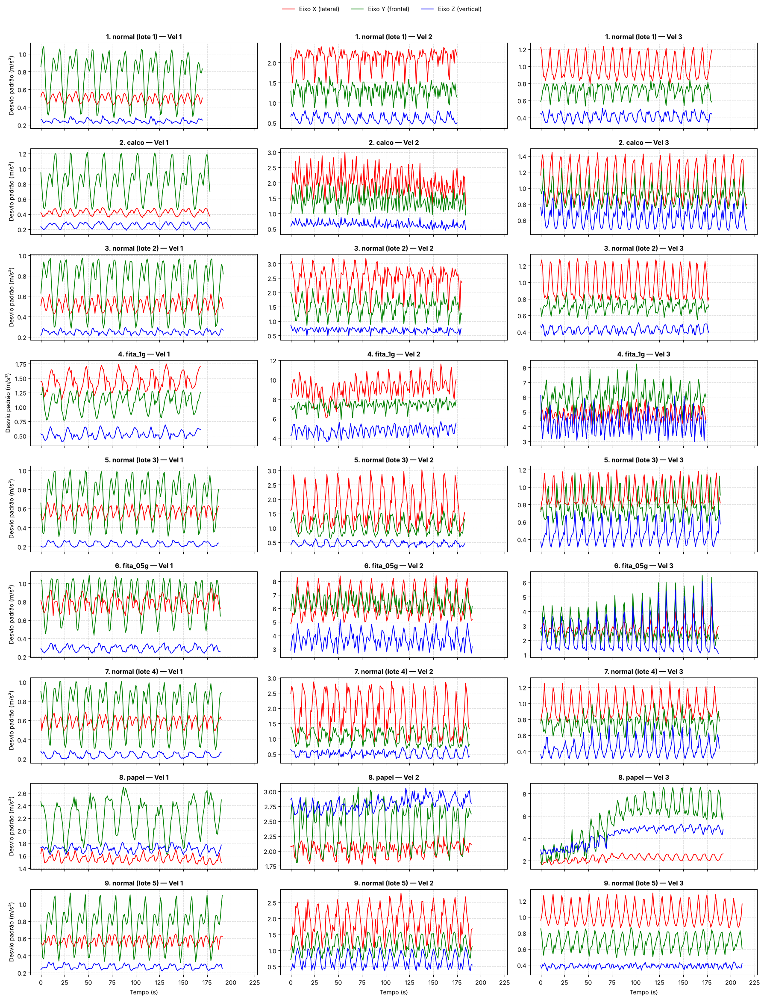

,std_medio_x,std_medio_y,std_medio_z,mudanca_%_x,mudanca_%_y,mudanca_%_z
base,,,,,,
ventilador_normal_vel_1_lote_1,0.494,0.741,0.241,-3.550,-3.282,-1.495
ventilador_normal_vel_2_lote_1,2.108,1.284,0.608,0.677,-1.454,-3.460
ventilador_normal_vel_3_lote_1,0.993,0.714,0.408,0.001,0.898,2.837
calco_vel_1,0.422,0.832,0.251,1.103,3.893,0.595
calco_vel_2,2.037,1.427,0.647,-10.051,-6.219,-10.068
calco_vel_3,1.058,0.898,0.629,-2.606,-2.238,-3.409
ventilador_normal_vel_1_lote_2,0.511,0.702,0.246,0.634,-6.104,-0.317
ventilador_normal_vel_2_lote_2,2.462,1.481,0.681,0.289,0.253,-6.082
ventilador_normal_vel_3_lote_2,0.970,0.708,0.424,-0.861,0.005,2.145


In [21]:
std_por_base = {nome: calcular_std_por_segundo(df) for nome, df in bases.items()}
plotar_std_por_segundo(std_por_base, catalogo)
display(resumir_estabilidade(std_por_base).round(3))

### Conclusões do Passo 6 (nesta execução)

**1. O ciclo da oscilação aparece em todas as bases** (o "serrilhado" regular), como nas coletas anteriores: cerca de 17 s na Vel 1 e cerca de 10 s na Vel 3 (contando os picos nos gráficos). Esperado, já que a oscilação ficou ligada.

**2. Não há degraus de troca de velocidade:** cada base tem uma velocidade só.

**3. Dentro de cada gravação o normal quase não muda de patamar.** A mudança do primeiro para o último terço fica entre −6% e +7% nos 15 normais, com uma exceção (N4 Vel 2, eixo X, −16%). **Isso é diferente da coleta anterior**, em que o normal da Vel 2 crescia 84% durante a gravação. Aqui não vemos aquecimento dentro das gravações; o que muda aparece **entre os lotes** (Passo 10).

**4. Três bases têm mudança de patamar ou comportamento próprio:**

| Base | O que acontece |
| --- | --- |
| **papel Vel 3** | começa com vibração baixa e muda de patamar entre cerca de 50 e 75 s: o desvio padrão em Y vai de ~2 para 6–8 m/s² e o de Z de ~3 para ~5 (mudança do primeiro para o último terço: X +16%, Y +114%, Z +53%). Parece o papel se ajeitando contra a hélice, como o papel Vel 2 da coleta anterior |
| **fita 0,5 g Vel 3** | rajadas regulares a cada ~10 s no eixo Z (o desvio padrão por segundo sobe de 1–2 para até 6 m/s²) |
| **calço Vel 2** | o desvio padrão cai cerca de 10% ao longo da gravação (−10% em X e em Z) |

**5. O formato do ciclo no eixo Z da Vel 3 muda de lote para lote no normal:** N3 e N4 mostram picos regulares em Z a cada ciclo, enquanto N1, N2 e N5 ficam quase planos. O calço Vel 3 também tem esse ciclo marcado em Z. Ou seja, o "normal" da Vel 3 não tem um formato único.

**O que isso significa para os próximos notebooks:**
* O normal precisa ser descrito pelos **5 lotes**, e não por um lote só.
* Para cada anomalia, vale comparar com **os normais vizinhos na sessão** e também com o conjunto dos 5.
* A fita 0,5 g Vel 3 e o papel Vel 3 têm trechos diferentes do resto da própria gravação; o teste trancado por blocos do Notebook 05 precisa levar isso em conta.

## Passo 7 — Features no domínio do tempo (desvio padrão, curtose e pico)

**O que buscamos:** resumir cada janela de `JANELA_S` segundos (sem sobreposição) em poucos números e ver **quais bases já se separam** só com isso. São as mesmas 9 features de tempo do dataset do grupo, calculadas depois de remover o componente DC:

* **Desvio padrão (`std`):** intensidade da vibração.
* **Curtose (`kurt`, definição de Fisher):** perto de 0 quando o sinal se parece com uma distribuição normal. Valores positivos indicam picos raros e fortes, como impactos.
* **Pico (`pico`):** maior valor absoluto da janela, ou seja, a amplitude máxima.

A última janela incompleta de cada base é descartada.

* **7.1 — Boxplots:** uma caixa por base. Caixas que não se sobrepõem indicam que a feature separa aquelas bases.
* **7.2 — Dispersão 3D do desvio padrão:** cada ponto é uma janela (cor = velocidade, símbolo = condição). Grupos separados no espaço indicam bases distinguíveis.

In [22]:
def calcular_features_tempo(df, janela_s=JANELA_S):
    """Calcula std, curtose e pico de cada eixo, em cada janela sem sobreposição.

    Devolve uma tabela com uma linha por janela e as colunas std_x, kurt_x, pico_x, std_y, ...
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)

    colunas = {}
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]
    return pd.DataFrame(colunas)


def calcular_features_de_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Junta as features de todas as bases numa só tabela, com as colunas base, condicao e velocidade."""
    tabelas = []
    for nome, df in bases.items():
        features = calcular_features_tempo(df, janela_s)
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
    return pd.concat(tabelas, ignore_index=True)

In [23]:
features_tempo = calcular_features_de_todas_as_bases(bases, catalogo)
colunas_features = [c for c in features_tempo.columns if c.split("_")[0] in ("std", "kurt", "pico")]

print(f"Janelas por base ({JANELA_S} s cada):")
display(features_tempo.groupby("base").size().to_frame("janelas"))
print("Média de cada feature por base:")
display(features_tempo.groupby("base")[colunas_features].mean().round(3))

Janelas por base (5 s cada):


,janelas
base,
calco_vel_1,35
calco_vel_2,37
calco_vel_3,43
fita_05g_vel_1,38
fita_05g_vel_2,38
fita_05g_vel_3,37
fita_1g_vel_1,33
fita_1g_vel_2,35
fita_1g_vel_3,35


Média de cada feature por base:


,std_x,kurt_x,pico_x,std_y,kurt_y,pico_y,std_z,kurt_z,pico_z
base,,,,,,,,,
calco_vel_1,0.537,-0.047,2.021,0.886,-0.863,2.363,0.256,-0.391,0.839
calco_vel_2,2.115,-0.319,7.139,1.496,0.320,5.818,0.655,-0.114,2.284
calco_vel_3,1.209,-0.135,4.110,1.010,-0.260,3.385,0.644,-0.473,2.125
fita_05g_vel_1,0.822,-0.335,2.583,0.840,-0.516,2.645,0.292,0.069,1.070
fita_05g_vel_2,6.394,-0.805,19.083,6.430,-0.634,18.353,3.731,0.940,15.992
fita_05g_vel_3,2.800,1.185,10.733,3.072,0.811,12.353,2.308,2.060,10.408
fita_1g_vel_1,1.467,-0.793,3.990,1.089,-0.464,3.353,0.526,-0.560,1.617
fita_1g_vel_2,9.150,-0.872,25.122,7.364,-0.282,22.991,4.761,1.710,20.170
fita_1g_vel_3,4.859,0.125,16.411,6.013,0.067,20.753,4.311,0.038,14.860


### 7.1 — Boxplots das features

As caixas seguem a **ordem da sessão** (N1 V1, N1 V2, N1 V3, calco V1, ...). Nos rótulos, N1 a N5 são os lotes de normal.

In [24]:
def plotar_boxplots_features(features, ordem_bases, rotulos=None):
    """Grade 3x3: linhas = std, curtose e pico; colunas = eixos X, Y e Z. Uma caixa por base.

    rotulos: nomes curtos que aparecem embaixo das caixas (por padrão, o nome da base)."""
    rotulos = rotulos if rotulos is not None else ordem_bases
    tipos = [("std", "Desvio padrão", UNIDADE), ("kurt", "Curtose", "adimensional"), ("pico", "Pico", UNIDADE)]
    fig, axs = plt.subplots(len(tipos), len(EIXOS), figsize=(26, 13))
    for i, (chave, titulo, unidade) in enumerate(tipos):
        for j, eixo in enumerate(EIXOS):
            ax = axs[i, j]
            dados = [features.loc[features["base"] == base, f"{chave}_{eixo}"] for base in ordem_bases]
            ax.boxplot(dados, tick_labels=rotulos)
            ax.set_title(f"{titulo} — {NOMES_EIXOS[eixo]}", fontsize=11, fontweight="bold")
            ax.set_ylabel(unidade)
            ax.tick_params(axis="x", rotation=60, labelsize=8)
            for rotulo in ax.get_xticklabels():
                rotulo.set_ha("right")
    plt.tight_layout()
    plt.show()

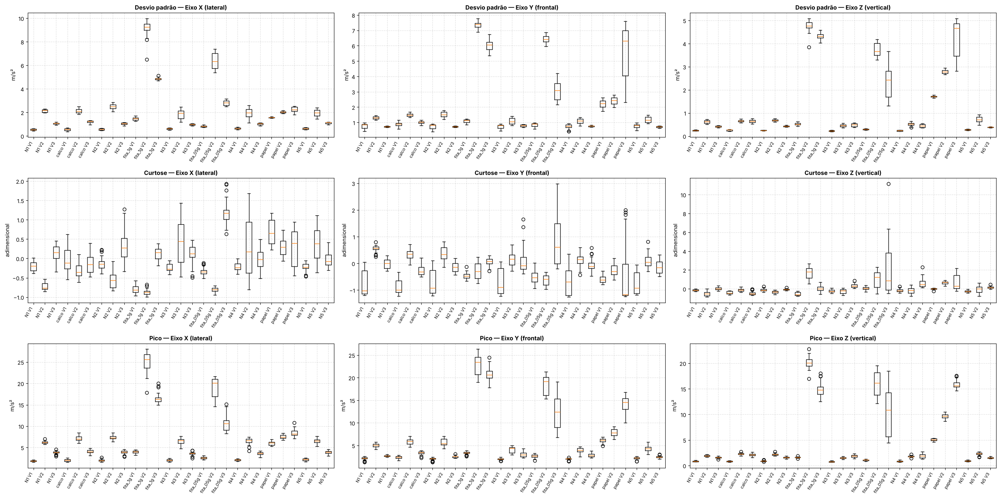

In [25]:
ordem_bases = list(bases.keys())
plotar_boxplots_features(features_tempo, ordem_bases, catalogo.loc[ordem_bases, "rotulo"].tolist())

### 7.2 — Dispersão 3D do desvio padrão por janela, em grupos

**O que buscamos:** ver, só com a intensidade da vibração nos três eixos, **o que já se separa**. Cada ponto é uma janela, posicionada pelo desvio padrão em X, Y e Z. **Cor = velocidade**, **símbolo = condição**.

Olhamos os mesmos pontos em seis recortes, do mais simples ao mais misturado:

1. **Apenas normal:** as três velocidades do ventilador saudável se separam?
2. **Cada anomalia separada** (um painel por falha): dentro de cada falha, as velocidades continuam se separando, ou a falha as embaralha?
3. **Todas as anomalias juntas:** as falhas se misturam entre si?
4. **Tudo junto:** normal e falhas no mesmo espaço.

**Como ler:** grupos de cores separados = as velocidades se distinguem; grupos de símbolos separados = as condições se distinguem. Cada painel tem a **sua própria escala**, para que grupos pequenos (como o normal) não fiquem espremidos.

**Duas versões:** a primeira figura usa a escala original (m/s²). Na segunda, os eixos estão em **escala logarítmica** (log10 do desvio padrão), que "abre" a região das vibrações pequenas, onde ficam o normal e a porca frouxa, e evita que a fita, muito mais forte, domine o espaço. É a mesma ideia do log usado nos Notebooks 03 e 04.

In [26]:
def plotar_dispersao_3d_std(features, catalogo):
    """Cada ponto é uma janela, nas coordenadas (std_x, std_y, std_z).

    Cor = velocidade. Símbolo = condição.
    """
    condicoes = sorted(catalogo["condicao"].unique())
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    for nome, grupo in features.groupby("base"):
        condicao = catalogo.loc[nome, "condicao"]
        velocidade = catalogo.loc[nome, "velocidade"]
        ax.scatter(
            grupo["std_x"], grupo["std_y"], grupo["std_z"],
            color=CORES_VELOCIDADE.get(velocidade, "gray"),
            marker=MARCADORES_CONDICAO[condicoes.index(condicao) % len(MARCADORES_CONDICAO)],
            alpha=0.6, s=28, label=nome,
        )
    ax.set_xlabel(f"std X ({UNIDADE})")
    ax.set_ylabel(f"std Y ({UNIDADE})")
    ax.set_zlabel(f"std Z ({UNIDADE})")
    ax.set_title(f"Desvio padrão por janela de {JANELA_S} s", fontsize=13, fontweight="bold")
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

def montar_grupos_3d(catalogo, condicao_normal=CONDICAO_NORMAL):
    """Lista de (título, condições) para os painéis: normal, cada anomalia, todas as anomalias e tudo junto."""
    anomalias = [c for c in sorted(catalogo["condicao"].unique()) if c != condicao_normal]
    grupos = [("Apenas normal", [condicao_normal])]
    grupos += [(f"Só {anomalia}", [anomalia]) for anomalia in anomalias]
    grupos += [("Todas as anomalias juntas", anomalias), ("Tudo junto", [condicao_normal] + anomalias)]
    return grupos


def plotar_dispersoes_3d_por_grupo(features, catalogo, grupos, em_log=False, colunas_fig=3):
    """Um gráfico 3D (std_x, std_y, std_z) por grupo de condições. Cor = velocidade, símbolo = condição."""
    condicoes = sorted(catalogo["condicao"].unique())
    transformar = np.log10 if em_log else (lambda valores: valores)
    sufixo = "log10 " if em_log else ""
    linhas = int(np.ceil(len(grupos) / colunas_fig))
    fig = plt.figure(figsize=(6.5 * colunas_fig, 5.8 * linhas))
    for k, (titulo, condicoes_do_grupo) in enumerate(grupos, start=1):
        ax = fig.add_subplot(linhas, colunas_fig, k, projection="3d")
        na_legenda = set()                      # os 5 lotes de normal repetem condição e velocidade: uma entrada só
        for nome, grupo in features[features["condicao"].isin(condicoes_do_grupo)].groupby("base"):
            condicao = catalogo.loc[nome, "condicao"]
            velocidade = catalogo.loc[nome, "velocidade"]
            ax.scatter(transformar(grupo["std_x"]), transformar(grupo["std_y"]), transformar(grupo["std_z"]),
                       color=CORES_VELOCIDADE.get(velocidade, "gray"),
                       marker=MARCADORES_CONDICAO[condicoes.index(condicao) % len(MARCADORES_CONDICAO)],
                       alpha=0.55, s=16, label=None if f"{condicao} V{velocidade}" in na_legenda else f"{condicao} V{velocidade}")
            na_legenda.add(f"{condicao} V{velocidade}")
        ax.set_xlabel(f"{sufixo}std X", fontsize=8)
        ax.set_ylabel(f"{sufixo}std Y", fontsize=8)
        ax.set_zlabel(f"{sufixo}std Z", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.set_title(titulo, fontsize=11, fontweight="bold")
        ax.legend(loc="upper left", fontsize=6, ncol=2 if len(condicoes_do_grupo) > 2 else 1)
    escala = "escala logarítmica (log10 do desvio padrão)" if em_log else f"escala original ({UNIDADE})"
    fig.suptitle(f"Desvio padrão por janela de {JANELA_S} s — {escala}", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

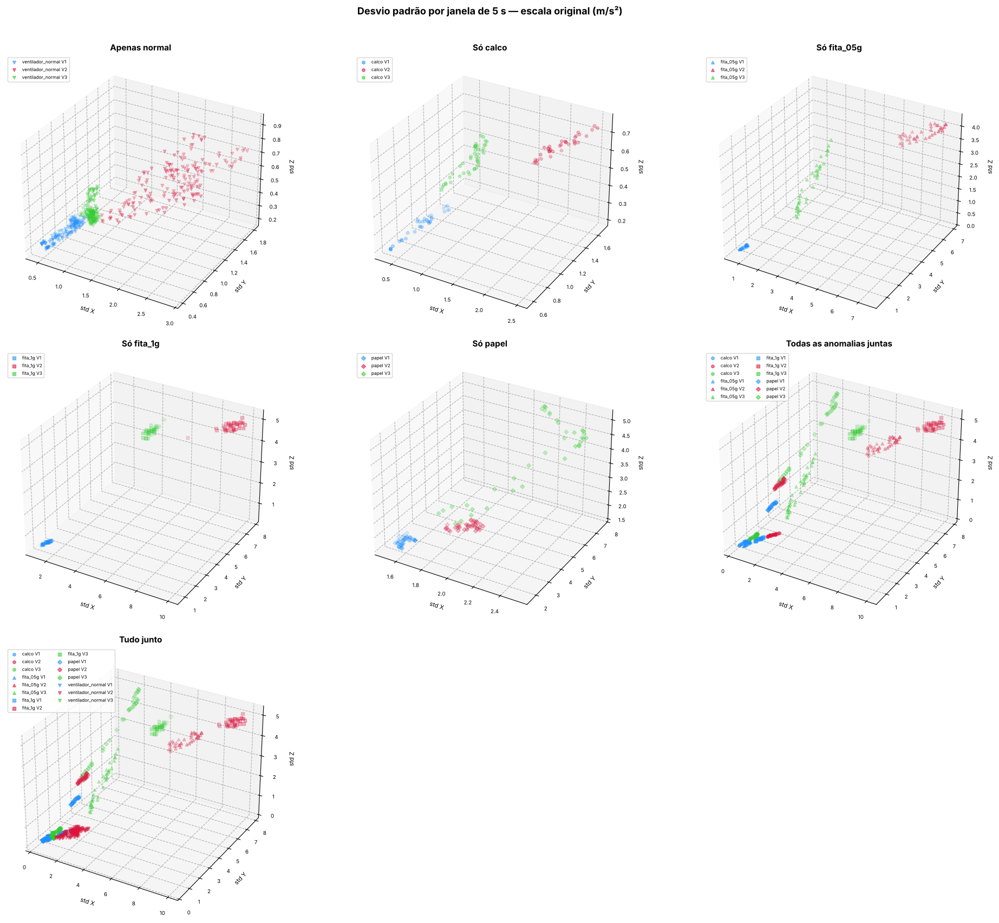

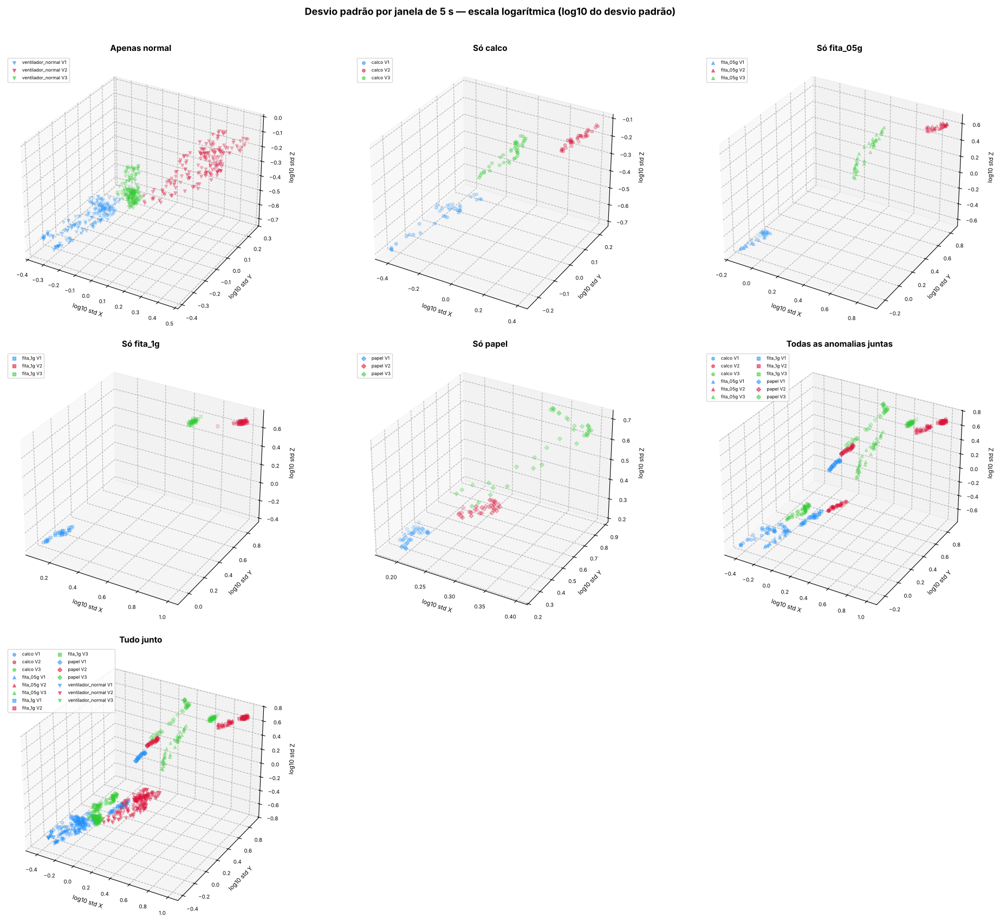

In [27]:
grupos_3d = montar_grupos_3d(catalogo)
plotar_dispersoes_3d_por_grupo(features_tempo, catalogo, grupos_3d, em_log=False)
plotar_dispersoes_3d_por_grupo(features_tempo, catalogo, grupos_3d, em_log=True)

### Conclusões do Passo 7 (nesta execução)

**Média do desvio padrão no eixo X** (m/s²). Para o normal, a média dos 5 lotes e, entre parênteses, a menor e a maior média entre os lotes:

| | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| normal (5 lotes) | 0,59 (0,54–0,63) | 2,08 (1,85–2,51) | 1,04 (0,98–1,11) |
| calço | 0,54 | 2,12 | 1,21 |
| fita 0,5 g | 0,82 | 6,39 | 2,80 |
| fita 1 g | 1,47 | 9,15 | 4,86 |
| papel | 1,57 | 2,04 | 2,24 |

* **A diferença entre lotes de normal é de 10% a 35% do valor** (por exemplo, Vel 2: de 1,85 a 2,51). É o tamanho da "régua" contra a qual cada anomalia precisa se destacar.
* **Fita:** cresce com a massa e com a velocidade. A de 1 g fica de 4 a 5 vezes o normal nas Vel 2 e 3; a de 0,5 g, de 2,7 a 3,1 vezes. Na Vel 1 é de 1,4 vez (0,5 g) a 2,5 vezes (1 g).
* **Papel:** 2,7 vezes o normal na Vel 1, 2,2 vezes na Vel 3, e **igual ao normal em X na Vel 2**. Na Vel 2 ele se destaca nos eixos Y e Z (o desvio padrão de Z é 4,7 vezes o normal).
* **Calço:** de 0,9 a 1,2 vez o normal em X. Só na Vel 3 o eixo Z sai da faixa dos lotes (0,64 contra 0,39 a 0,48). Nas Vel 1 e 2 fica dentro.
* **Curtose:** perto de zero na maioria das bases. A fita na Vel 3 chega a +1,2 (X) e +2,1 (Z). **No normal da Vel 2, a curtose em X vai de −0,72 (N1) a +0,40 (N3)**: mais uma feature que muda de lote para lote.

**Dispersão 3D (7.2), painel por painel:**

* **Apenas normal:** as três velocidades formam três faixas distintas. Cada nuvem é alongada na diagonal (os três eixos sobem e descem juntos), provavelmente pelo ciclo da oscilação do Passo 6, e a da Vel 2 é a mais espalhada.
* **Só calço:** três faixas com o mesmo desenho do normal.
* **Só fita (0,5 g e 1 g):** a Vel 1 fica perto do normal; as Vel 2 e 3 ficam muito acima. A de 1 g sobe mais.
* **Só papel:** três grupos distintos; a Vel 3 é espalhada pela mudança de patamar do Passo 6.
* **Todas as anomalias juntas:** a fita (Vel 2 e 3) fica isolada no alto, o papel no meio e o calço embaixo, junto das Vel 1.
* **Tudo junto (escala logarítmica):** **o normal e o calço ficam sobrepostos** em cada velocidade, e a fita 0,5 g na Vel 1 também fica colada no normal. Fita 1 g, fita 0,5 g (Vel 2 e 3) e papel se destacam.

**Conclusão do 7.2:** com só o desvio padrão, **as velocidades se separam**, e **fita e papel se separam do normal** (exceto a fita na Vel 1). **O calço não se separa do normal só com intensidade**, e a fita 0,5 g na Vel 1 também não. Se forem separáveis, a diferença deve estar no espectro (Passo 8 e Notebook 02).

## Passo 8 — FFT com janela de Hanning

**O que buscamos:** descobrir **em quais frequências** a vibração acontece. A FFT decompõe o sinal em frequências, e a altura de cada pico mostra a força daquela frequência.

Ao recortar o sinal de forma abrupta, as bordas "cortam" as ondas ao meio e criam ruído falso na base dos picos (*vazamento espectral*). A **janela de Hanning** suaviza as bordas antes da FFT e deixa os picos mais finos e nítidos. O espectro final ignora frequências abaixo de `F_MIN_HZ` (deriva lenta do sensor) e acima de `F_MAX_HZ`.

* **8.1 — Efeito da janela de Hanning no tempo**, numa única base.
* **8.2 — FFT sem janela vs. com Hanning**, na mesma base.
* **8.3 — Espectro de todas as bases**, com a mesma escala vertical por velocidade, para comparar normal e anomalia.

In [28]:
def calcular_fft(sinal_1d, usar_hanning=True):
    """FFT de um eixo. Devolve (frequências em Hz, magnitude na mesma unidade do sinal).

    O sinal é centralizado em zero (remove a gravidade). A magnitude é compensada para que a altura
    do pico seja a amplitude da onda: fator 2/N sem janela e 4/N com Hanning, que perde metade da energia.
    """
    n = len(sinal_1d)
    centrado = sinal_1d - sinal_1d.mean()
    if usar_hanning:
        espectro = np.fft.rfft(centrado * np.hanning(n))
        fator = 4.0 / n
    else:
        espectro = np.fft.rfft(centrado)
        fator = 2.0 / n
    frequencias = np.fft.rfftfreq(n, d=1.0 / TAXA_AMOSTRAGEM_HZ)
    return frequencias, np.abs(espectro) * fator


def calcular_espectro_da_base(df, inicio_s=INICIO_FFT_S, janela_s=JANELA_S, usar_hanning=True):
    """FFT dos três eixos numa janela da base, só entre F_MIN_HZ e F_MAX_HZ.

    Devolve (frequências, {eixo: magnitude}).
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    trecho = df[EIXOS].iloc[inicio: inicio + tamanho]
    if len(trecho) < tamanho:
        raise ValueError(f"A base não tem {janela_s} s a partir do segundo {inicio_s}.")
    magnitudes = {}
    for eixo in EIXOS:
        frequencias, magnitudes[eixo] = calcular_fft(trecho[eixo].to_numpy(), usar_hanning)
    faixa = (frequencias > F_MIN_HZ) & (frequencias <= F_MAX_HZ)
    return frequencias[faixa], {eixo: magnitudes[eixo][faixa] for eixo in EIXOS}


def plotar_efeito_hanning(df, nome, eixo="x", inicio_s=INICIO_FFT_S, janela_s=JANELA_S):
    """Mostra, no tempo, o sinal centralizado antes e depois de multiplicar pela janela de Hanning."""
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    sinal_1d = df[eixo].to_numpy()[inicio: inicio + tamanho]
    centrado = sinal_1d - sinal_1d.mean()
    janela = np.hanning(tamanho)
    tempo = np.arange(tamanho) / TAXA_AMOSTRAGEM_HZ

    plt.figure(figsize=(14, 4))
    plt.plot(tempo, centrado, color="lightgray", label="Sinal centralizado (bordas bruscas)")
    plt.plot(tempo, centrado * janela, color="red", alpha=0.9, label="Com janela de Hanning (bordas suaves)")
    plt.plot(tempo, janela * np.abs(centrado).max(), color="black", linestyle="--", label="Formato da janela")
    plt.title(f"Efeito da janela de Hanning — {nome}, {NOMES_EIXOS[eixo]}", fontsize=13, fontweight="bold")
    plt.xlabel("Tempo (s)")
    plt.ylabel(f"Aceleração ({UNIDADE})")
    plt.legend(loc="upper right")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()


def plotar_fft_sem_janela_vs_hanning(df, nome):
    """Grade 3x2: cada linha é um eixo; à esquerda a FFT sem janela, à direita com Hanning."""
    fig, axs = plt.subplots(len(EIXOS), 2, figsize=(18, 9), sharex=True, sharey="row")
    versoes = [(False, "FFT sem janela"), (True, "FFT com Hanning")]
    for coluna, (usar_hanning, titulo) in enumerate(versoes):
        frequencias, magnitudes = calcular_espectro_da_base(df, usar_hanning=usar_hanning)
        for linha, eixo in enumerate(EIXOS):
            ax = axs[linha, coluna]
            ax.plot(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], linewidth=1.1)
            ax.fill_between(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], alpha=0.2)
            if linha == 0:
                ax.set_title(titulo, fontsize=12, fontweight="bold")
            if coluna == 0:
                ax.set_ylabel(f"{NOMES_EIXOS[eixo]}\nMagnitude ({UNIDADE})")
    axs[-1, 0].set_xlabel("Frequência (Hz)")
    axs[-1, 1].set_xlabel("Frequência (Hz)")
    fig.suptitle(f"{nome} — janela de {JANELA_S} s a partir do segundo {INICIO_FFT_S}", y=0.995, fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()


def desenhar_marcas_de_frequencia(ax, nome, freq_1x_por_base, n_harmonicas, freqs_referencia_hz):
    """Desenha linhas verticais opcionais: 1X e harmônicas da base e frequências de referência."""
    freq_1x = freq_1x_por_base.get(nome)
    if freq_1x is not None:
        for k in range(1, n_harmonicas + 1):
            ax.axvline(k * freq_1x, color="orange", linestyle="--", alpha=0.8, label=f"{k}X ({k * freq_1x:.1f} Hz)")
    for freq in freqs_referencia_hz:
        ax.axvline(freq, color="black", linestyle=":", alpha=0.6, label=f"{freq} Hz")


def plotar_espectros_das_bases(bases, catalogo, freq_1x_por_base, n_harmonicas, freqs_referencia_hz):
    """Grade (condição x velocidade) com o espectro dos 3 eixos de cada base.

    A escala vertical é compartilhada por coluna (mesma velocidade), para comparar normal e anomalia.
    """
    fig, axs, celulas = criar_grade(
        catalogo, largura=7, altura=3.6, sharex=True, sharey="col",
        rotulo_x="Frequência (Hz)", rotulo_y=f"Magnitude ({UNIDADE})",
    )
    for ax, nome in celulas:
        frequencias, magnitudes = calcular_espectro_da_base(bases[nome])
        for eixo in EIXOS:
            ax.plot(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], linewidth=1, alpha=0.85, label=NOMES_EIXOS[eixo])
        desenhar_marcas_de_frequencia(ax, nome, freq_1x_por_base, n_harmonicas, freqs_referencia_hz)
        ax.legend(loc="upper right", fontsize=7)
    fig.suptitle(f"Espectro com Hanning — janela de {JANELA_S} s a partir do segundo {INICIO_FFT_S}", y=0.995, fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()

def calcular_espectro_medio(df, janela_s=JANELA_S, usar_hanning=True):
    """Média dos espectros de todas as janelas da base (sem sobreposição), só entre F_MIN_HZ e F_MAX_HZ.

    Devolve (frequências, {eixo: magnitude média}). Ruído aleatório se cancela na média; picos que se repetem ficam.
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    soma = None
    for k in range(n_janelas):
        frequencias, magnitudes = calcular_espectro_da_base(df, inicio_s=k * janela_s, janela_s=janela_s, usar_hanning=usar_hanning)
        soma = magnitudes if soma is None else {eixo: soma[eixo] + magnitudes[eixo] for eixo in EIXOS}
    return frequencias, {eixo: soma[eixo] / n_janelas for eixo in EIXOS}


def plotar_espectros_medios(bases, catalogo):
    """Grade (condição x velocidade) com o espectro médio de todas as janelas, mesma escala vertical por velocidade."""
    fig, axs, celulas = criar_grade(catalogo, largura=6.5, altura=3.2, sharex=True, sharey="col",
                                    rotulo_x="Frequência (Hz)", rotulo_y=f"Magnitude ({UNIDADE})")
    for ax, nome in celulas:
        frequencias, magnitudes = calcular_espectro_medio(bases[nome])
        for eixo in EIXOS:
            ax.plot(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], linewidth=0.9, label=NOMES_EIXOS[eixo])
        ax.legend(loc="upper right", fontsize=7)
    fig.suptitle(f"Espectro médio de todas as janelas de {JANELA_S} s (Hanning)", y=0.995, fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()

### 8.1 — Efeito da janela de Hanning (uma base)

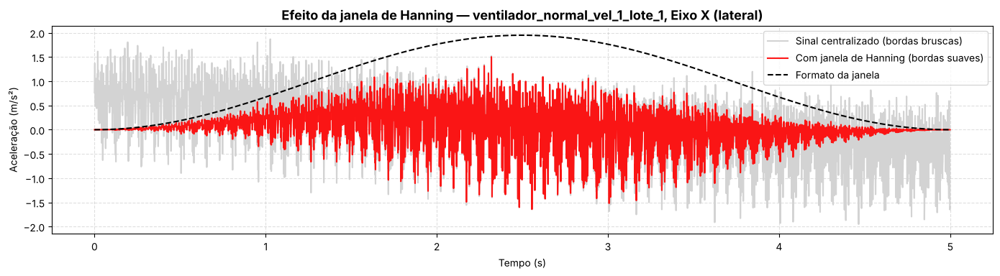

In [29]:
nome_exemplo = BASE_EXEMPLO if BASE_EXEMPLO is not None else list(bases.keys())[0]
plotar_efeito_hanning(bases[nome_exemplo], nome_exemplo)

### 8.2 — FFT sem janela vs. com Hanning (uma base)

Repare que, com Hanning, a base dos picos fica mais limpa.

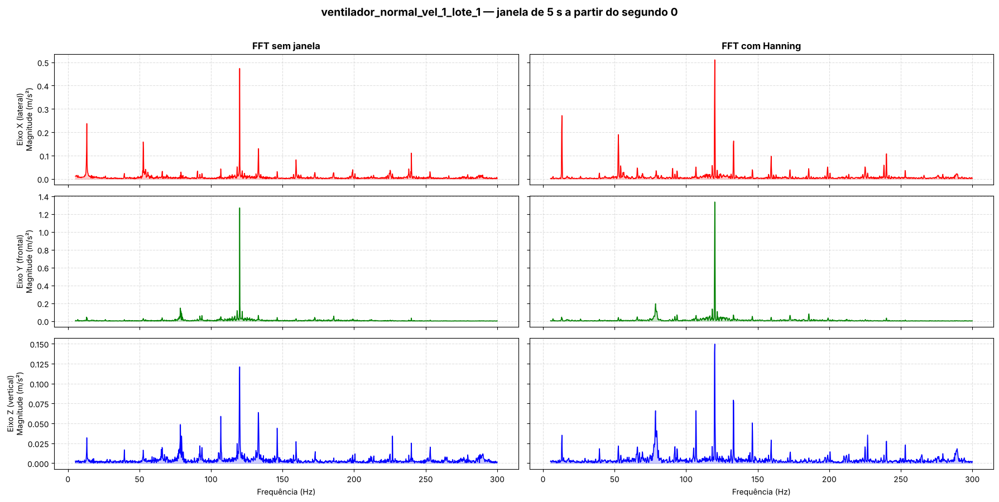

In [30]:
plotar_fft_sem_janela_vs_hanning(bases[nome_exemplo], nome_exemplo)

### 8.3 — Espectro de todas as bases

Os gráficos saem com as **linhas de 120 e 240 Hz marcadas** (pontilhadas): o orientador confirmou que são **componente elétrica**, e não rotação nem falha mecânica. Para marcar também a frequência de rotação (**1X**) e suas harmônicas:

1. Rode a célula abaixo e **olhe os gráficos**: o 1X costuma ser o primeiro pico forte em baixas frequências, e as harmônicas são múltiplos dele (2X, 3X, ...).
2. Anote o valor em Hz de cada base.
3. Na célula, descomente o bloco `FREQ_1X_POR_BASE` (selecione as linhas e use `Ctrl + /`), troque pelos valores que você viu e rode de novo.

Lembre que a rotação sobe durante a gravação nas Vel 1 e 2 (aquecimento), então um único valor de 1X por base vale só para o trecho analisado (`INICIO_FFT_S`). O Passo 10 mede a rotação janela por janela.

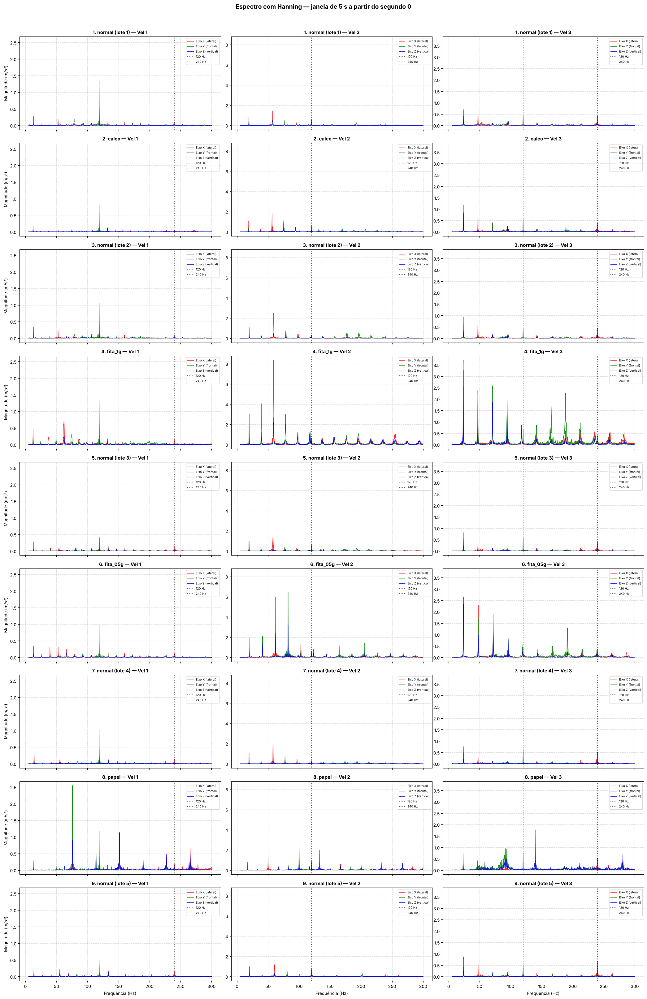

In [31]:
FREQ_1X_POR_BASE = {}              # sem marcas de 1X por padrão
N_HARMONICAS = 4                   # quantos múltiplos desenhar (1X, 2X, 3X, 4X)
FREQS_REFERENCIA_HZ = [120, 240]   # linhas elétricas (2x e 4x os 60 Hz da rede), confirmadas pelo orientador

# FREQ_1X_POR_BASE = {
#     "ventilador_normal_vel_1_lote_1": 13.2,
#     "ventilador_normal_vel_2_lote_1": 19.2,
#     "ventilador_normal_vel_3_lote_1": 23.8,
# }

plotar_espectros_das_bases(bases, catalogo, FREQ_1X_POR_BASE, N_HARMONICAS, FREQS_REFERENCIA_HZ)

### Conclusões do Passo 8 (nesta execução)

**Atenção:** o espectro desta figura usa **uma janela de 5 s no começo de cada base** (`INICIO_FFT_S = 0`). Uma janela só carrega o ruído daquele trecho, então números como a altura dos picos variam bastante de uma gravação para outra e devem ser confirmados no 8.4.

* **A linha de 120 Hz aparece nas 27 bases, e a de 240 Hz também** (marcadas nas figuras). Como o orientador confirmou, são **elétricas** (2 e 4 vezes os 60 Hz da rede), e não rotação nem falha. Na Vel 1 o 120 Hz domina o eixo Y e, numa janela só, vale de 0,4 a 1,4 m/s² entre as gravações, **inclusive nos normais**, o que mostra o quanto uma janela só engana.
* **Normal:** espectro limpo, com picos pequenos em 1X e harmônicas, nos 5 lotes.
* **Fita:** "pentes" de picos nas harmônicas da rotação. Na Vel 2, o pico perto de 58 Hz (3X) chega a 8,4 m/s² no eixo X da fita 1 g e a cerca de 6 na de 0,5 g, contra 0,5 a 2,9 nos normais. Na Vel 3, o pente de ~23, 47, 70 e 94 Hz chega a 3,7 na fita 1 g.
* **Papel:** linhas estreitas e fortes em frequências próprias de cada velocidade. Na Vel 1, 75 Hz (2,5 m/s² no eixo Y), 115 e 152 Hz. Na Vel 3, uma banda larga de 85 a 100 Hz e um pico perto de 140 Hz. É o padrão de impacto repetido.
* **Calço:** parecido com o normal nas três velocidades. Os picos de 1X e 3X ficam **dentro da faixa dos normais** (por exemplo, na Vel 2 o pico perto de 58 Hz é de ~1,8 no calço, contra 0,5 a 2,9 nos normais, nesta janela).

### 8.4 — Espectro médio da gravação inteira

**Por que este gráfico existe:** o espectro do 8.3 usa **uma única janela de 5 s** (a partir de `INICIO_FFT_S`). Uma janela só mostra o que acontecia **naqueles 5 s**, e nos dados novos o começo de cada gravação é um momento especial: motor frio, rotação ainda subindo, e em algumas bases (fita V2, papel V2) a vibração ainda se acomodando. Além disso, uma janela só carrega todo o ruído aleatório daquele trecho.

**O que fazemos aqui:** calculamos o espectro de **todas as janelas** da base e tiramos a **média**. O ruído aleatório, que muda de janela para janela, se cancela. O que se repete (rotação, harmônicas, a linha de 120 Hz, as ressonâncias) fica. É o "retrato médio" da gravação.

**Uma limitação:** nas Vel 1 e 2 a rotação sobe com o aquecimento, então os picos das harmônicas ficam um pouco **alargados** na média (cada janela tem o pico num lugar um pouco diferente). Na Vel 3, que é estável, os picos ficam finos.

**Como ler:** compare com o 8.3. Se um pico aparece nos dois, ele é típico da base. Se aparece só no 8.3, era coisa daquele trecho inicial.

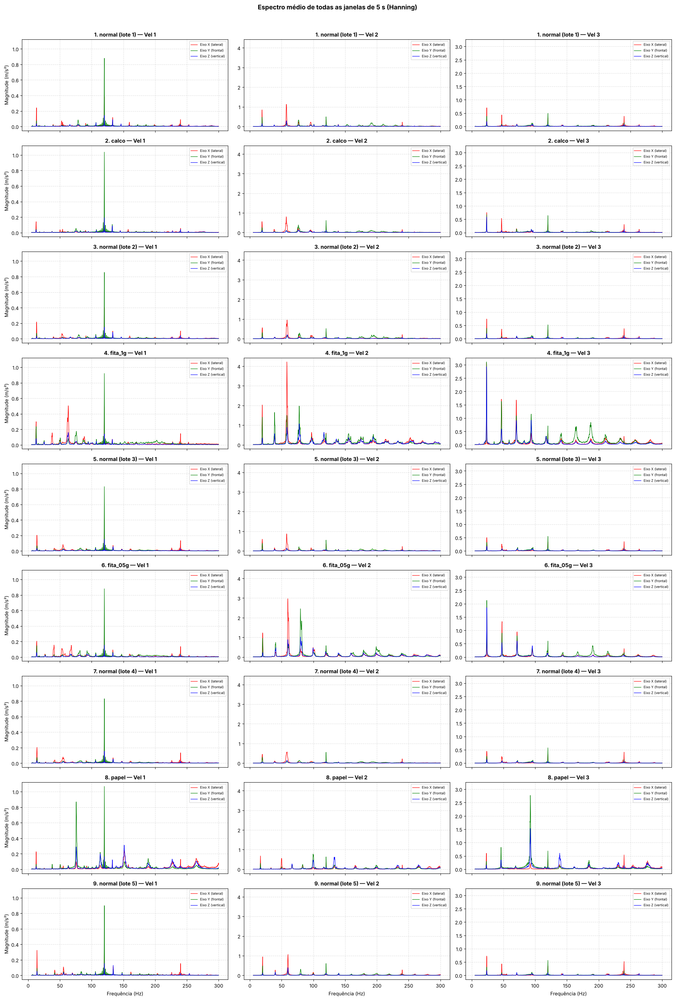

In [32]:
plotar_espectros_medios(bases, catalogo)

### Conclusões do Passo 8.4 (nesta execução)

**Com a média de todas as janelas, os espectros ficam limpos** e as diferenças entre as bases ficam mais claras.

* **120 Hz e 240 Hz nas 27 bases, com o mesmo tamanho em qualquer condição:** o 120 Hz fica em 0,8 a 1,1 m/s² no eixo Y na Vel 1 e em cerca de 0,5 a 0,6 nas Vel 2 e 3; o 240 Hz fica abaixo de 0,15 na Vel 1, perto de 0,2 na Vel 2 e de 0,35 a 0,5 no eixo X na Vel 3. Ou seja, **a amplitude muda com a velocidade e não com a condição**, o que reforça que são elétricas (como o orientador confirmou).
* **Normal, Vel 3 (rotação estável):** "pente" de picos finos em ~24, 48 e 72 Hz, com alturas parecidas nos 5 lotes (cerca de 0,45 a 0,75 no 1X, eixo X).
* **Normal, Vel 2:** o pico perto de 58 Hz (3X) muda **bastante de lote para lote**, de cerca de 0,55 (N4) a 1,1 m/s² (N1). Esse é o tamanho da variação que o normal tem sozinho.
* **Fita:** o mesmo pente fica de 3 a 6 vezes mais alto que o normal nas Vel 2 e 3. Na Vel 2 (fita 1 g), 58 Hz chega a ~4,2 no eixo X; na Vel 3, o 1X (~23 Hz) chega a ~3,1. **A fita 0,5 g tem o mesmo desenho com cerca de 70% da altura da de 1 g.**
* **Papel:** além das harmônicas, tem picos e bandas próprios. Vel 1: ~75 Hz (0,87 no eixo Y), ~152 Hz e uma banda perto de 265 Hz. Vel 3: pico forte perto de 92 Hz (2,8) e outro perto de 139 Hz. Vel 2: energia em 100 e 133 Hz.
* **Calço:** o espectro médio é **praticamente o do normal** nas três velocidades, sem picos novos. Se ele for separável, a diferença é pequena e está nas amplitudes, não em frequências novas.

**Para os próximos notebooks:** as features de FFT são calculadas janela por janela, e o Notebook 02 mede quais faixas separam as condições apesar do ruído de cada janela e das diferenças entre lotes de normal.

## Passo 9 — Espectrograma

**O que buscamos:** ver como as frequências **evoluem no tempo**. A FFT do Passo 8 olha uma janela só. O espectrograma (STFT) divide a base em fatias de 2 s (com Hanning e 1 s de sobreposição) e mostra a magnitude de cada frequência em cada instante: eixo horizontal = tempo, eixo vertical = frequência, cor = magnitude.

Como ler:

* **Linhas horizontais constantes:** frequências fixas. Numa base estável, tanto a rotação quanto o ruído elétrico aparecem assim.
* **Linhas que sobem, descem ou dão saltos:** a velocidade mudou ou oscilou durante a base.
* **Faixas que aparecem só em parte do tempo:** perturbação no teste.

Todos os gráficos usam a **mesma escala de cor**, então cores mais fortes significam vibração maior em qualquer base. O eixo analisado é `EIXO_ESPECTROGRAMA`.

In [33]:
def calcular_espectrograma(serie, nperseg_s=2, noverlap_s=1):
    """Espectrograma de um eixo (fatias de nperseg_s com Hanning), entre F_MIN_HZ e F_MAX_HZ.

    Devolve (frequências, tempos, magnitude), com a magnitude na unidade do sinal.
    """
    frequencias, tempos, potencia = signal.spectrogram(
        serie - serie.mean(),
        fs=TAXA_AMOSTRAGEM_HZ,
        window="hann",
        nperseg=int(nperseg_s * TAXA_AMOSTRAGEM_HZ),
        noverlap=int(noverlap_s * TAXA_AMOSTRAGEM_HZ),
        scaling="spectrum",
    )
    magnitude = np.sqrt(potencia) * 2.0
    faixa = (frequencias > F_MIN_HZ) & (frequencias <= F_MAX_HZ)
    return frequencias[faixa], tempos, magnitude[faixa, :]

In [34]:
def plotar_espectrogramas(bases, catalogo, eixo=EIXO_ESPECTROGRAMA):
    """Grade (condição x velocidade) com o espectrograma de um eixo, na mesma escala de cor.

    Usa imshow (uma imagem por base), que gasta muito menos memória que pcolormesh.
    """
    resultados = {nome: calcular_espectrograma(df[eixo].to_numpy()) for nome, df in bases.items()}
    valor_maximo = np.percentile(np.concatenate([m.ravel() for _, _, m in resultados.values()]), 99.5)

    fig, axs, celulas = criar_grade(
        catalogo, largura=7, altura=3.6, sharex=False, sharey=True,
        rotulo_x="Tempo (s)", rotulo_y="Frequência (Hz)",
    )
    for ax, nome in celulas:
        frequencias, tempos, magnitude = resultados[nome]
        grafico = ax.imshow(
            magnitude, origin="lower", aspect="auto", cmap="inferno", vmin=0, vmax=valor_maximo,
            interpolation="bilinear",
            extent=[tempos[0], tempos[-1], frequencias[0], frequencias[-1]],
        )
        ax.grid(False)
    fig.suptitle(f"Espectrograma — {NOMES_EIXOS[eixo]}", y=0.995, fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    fig.colorbar(grafico, ax=axs, shrink=0.8, label=f"Magnitude ({UNIDADE})")
    plt.show()

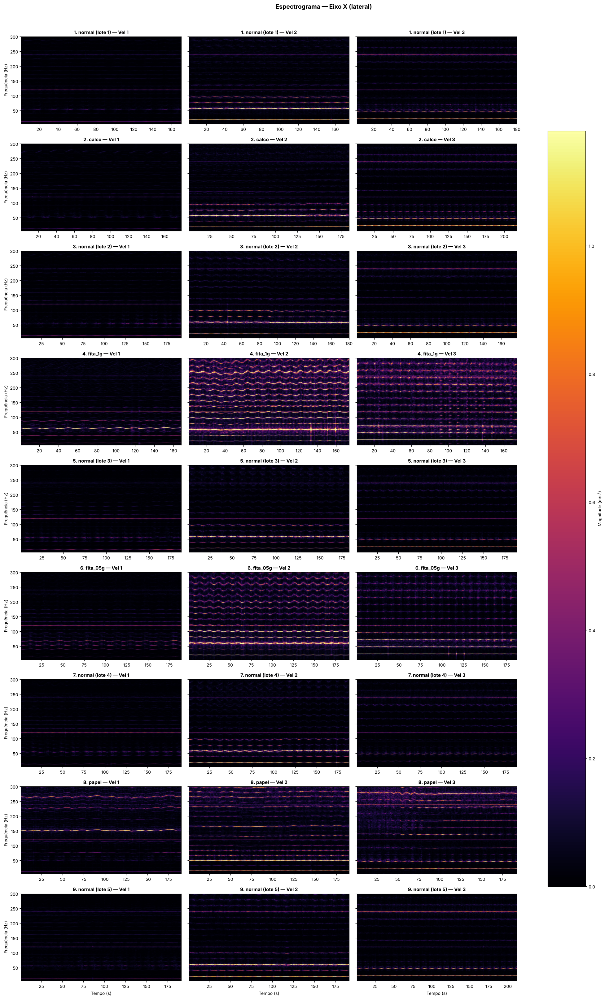

In [35]:
plotar_espectrogramas(bases, catalogo, eixo=EIXO_ESPECTROGRAMA)

### Conclusões do Passo 9 (nesta execução)

**O espectrograma mostra o que a média escondia:**

* **Todas as linhas ficam horizontais, nas 27 bases.** **Aqui as harmônicas não sobem durante a gravação**, ao contrário da coleta anterior (Vel 1 e 2 subindo com o aquecimento). A mudança de rotação aparece **entre os lotes**, e não dentro de cada gravação (Passo 10).
* **As linhas de 120 e 240 Hz são perfeitamente horizontais** em todas as bases e não acompanham a rotação, o que combina com a origem elétrica confirmada pelo orientador.
* **As linhas "ondulam" levemente** a cada ciclo da oscilação, e a ondulação fica bem visível na fita (Vel 1 e 2) e no papel Vel 1.
* **Fita 0,5 g e 1 g, Vel 2 e 3:** pentes de harmônicas fortes até 300 Hz. **Na Vel 3 aparecem faixas verticais** (rajadas de banda larga a cada cerca de 10 s), que são as rajadas do Passo 4.1, mais claras na fita 0,5 g.
* **Papel Vel 3:** os primeiros 60 a 75 s têm energia espalhada abaixo de 200 Hz e depois as linhas se organizam. É a mudança de patamar do Passo 6. No papel Vel 1, as linhas fortes ficam perto de 152 e 265 Hz.
* **Calço:** visualmente igual ao normal da mesma velocidade.

## Passo 10 — A sessão intercalada: os lotes de normal, a rotação e a inclinação

**O que buscamos:** responder a pergunta nova desta coleta: **o normal é sempre o mesmo ao longo da sessão?** Como não houve espera para o motor esfriar, os 5 lotes de normal podem ter rotação e vibração diferentes, e cada anomalia ficou entre dois normais. Se os normais mudam, **a comparação justa de uma anomalia é com os normais vizinhos**, e não com um "normal médio".

Olhamos três coisas, sempre **na ordem em que as gravações foram feitas** (N1, anomalia, N2, ...):

* **10.1 — Rotação (1X) por janela:** o pico do espectro entre `FAIXA_BUSCA_1X_HZ`, estimado em duas passadas (primeiro o pico de cada janela; depois só a até `DESVIO_MAX_1X_HZ` da rotação típica da base, para que o 2X ou uma ressonância não seja confundido com o 1X). Ela sobe quando o motor esquenta e **cai quando a falha freia o ventilador**.
* **10.2 — Intensidade (desvio padrão do eixo Z) por janela:** mostra quanto cada anomalia se afasta do normal e quanto os normais se afastam entre si.
* **10.3 — Componente estática (a média de X e Y):** é a **gravidade projetada nos eixos**, e muda quando o ventilador **inclina**. Ela é removida das features (o Passo 7 tira a média de cada janela), então **não entra nos modelos**. Aqui serve só para saber quais gravações mudaram a posição do ventilador (por exemplo, o calço).

Cada caixa é uma gravação (as 34 a 43 janelas dela). Azul = normal; laranja = anomalia.

In [36]:
def estimar_rotacao_por_janela(df, janela_s=JANELA_S, faixa_hz=FAIXA_BUSCA_1X_HZ, desvio_max_hz=DESVIO_MAX_1X_HZ):
    """Rotação (1X) de cada janela de janela_s segundos, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de faixa_hz, janela por janela. A mediana é a rotação típica da base.
    2ª passada: repete a busca só a até desvio_max_hz da rotação típica. Isso evita que, numa anomalia forte,
    o pico do 2X ou de outra frequência seja confundido com o 1X. Com janelas de 5 s, a resolução é de 0,2 Hz.
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho].reshape(n_janelas, tamanho, len(EIXOS))
    dados = dados - dados.mean(axis=1, keepdims=True)
    magnitude = np.abs(np.fft.rfft(dados * np.hanning(tamanho)[None, :, None], axis=1)).sum(axis=2)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)
    na_faixa = (frequencias >= faixa_hz[0]) & (frequencias <= faixa_hz[1])
    primeira = frequencias[na_faixa][magnitude[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= desvio_max_hz)
    return frequencias[perto][magnitude[:, perto].argmax(axis=1)]


def montar_tabela_da_sessao(bases, catalogo, features_tempo):
    """Uma linha por janela, com o bloco da sessão, a velocidade, a rotação (1X) e o desvio padrão de cada eixo."""
    partes = []
    for nome in catalogo.index:
        janelas = features_tempo.loc[features_tempo["base"] == nome, ["std_x", "std_y", "std_z"]].reset_index(drop=True)
        janelas["rotacao_hz"] = estimar_rotacao_por_janela(bases[nome])
        janelas.insert(0, "janela", np.arange(len(janelas)))
        janelas.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        janelas.insert(0, "bloco_curto", catalogo.loc[nome, "bloco_curto"])
        janelas.insert(0, "base", nome)
        partes.append(janelas)
    return pd.concat(partes, ignore_index=True)


def plotar_sessao(tabela, catalogo, linhas):
    """Grade com uma linha por medida e uma coluna por velocidade; uma caixa por bloco, na ordem da sessão.

    linhas: lista de (coluna, título, em_log). Normal em azul, anomalia em laranja.
    """
    blocos = list(dict.fromkeys(catalogo.sort_values("posicao_sessao")["bloco_curto"]))
    velocidades = sorted(tabela["velocidade"].unique())
    fig, axs = plt.subplots(len(linhas), len(velocidades), figsize=(6.5 * len(velocidades), 4 * len(linhas)), squeeze=False)
    for i, (coluna, titulo, em_log) in enumerate(linhas):
        for j, velocidade in enumerate(velocidades):
            ax = axs[i, j]
            dados = [tabela.loc[(tabela["velocidade"] == velocidade) & (tabela["bloco_curto"] == b), coluna] for b in blocos]
            caixas = ax.boxplot(dados, tick_labels=blocos, patch_artist=True, showfliers=False,
                                medianprops={"color": "black", "linewidth": 1.4})
            for caixa, bloco in zip(caixas["boxes"], blocos):
                caixa.set_facecolor("tab:blue" if re.fullmatch(r"N\d+", bloco) else "tab:orange")
                caixa.set_alpha(0.75)
            if em_log:
                ax.set_yscale("log")
            if i == 0:
                ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
            if j == 0:
                ax.set_ylabel(titulo)
            ax.tick_params(axis="x", rotation=45, labelsize=9)
    fig.suptitle("Uma caixa por gravação, na ordem da sessão (azul = normal, laranja = anomalia)", y=0.995, fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()

### 10.1 e 10.2 — Rotação e intensidade, gravação por gravação

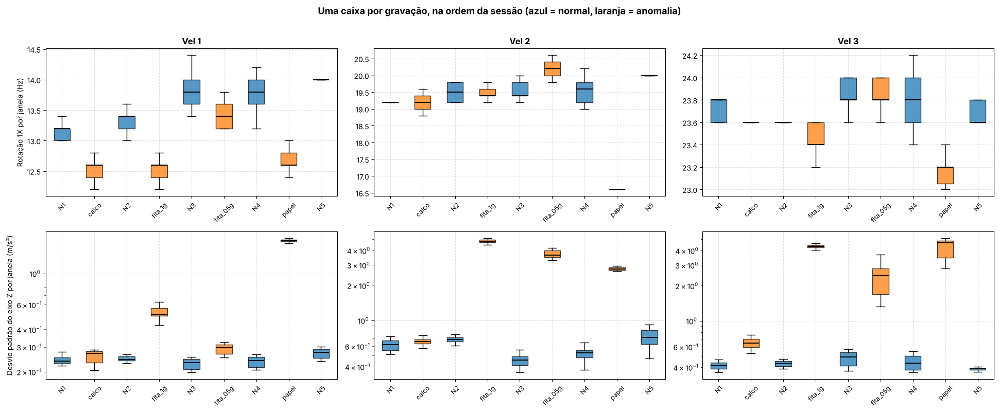

Rotação (1X) mediana de cada gravação, em Hz (linhas na ordem da sessão):


velocidade,1,2,3
bloco_curto,,,
N1,13.2,19.2,23.8
calco,12.6,19.2,23.6
N2,13.4,19.5,23.6
fita_1g,12.6,19.4,23.4
N3,13.8,19.4,23.8
fita_05g,13.4,20.2,23.8
N4,13.8,19.6,23.8
papel,12.6,16.6,23.2
N5,14.0,20.0,23.6


Desvio padrão mediano do eixo Z de cada gravação, em m/s²:


velocidade,1,2,3
bloco_curto,,,
N1,0.238,0.619,0.413
calco,0.271,0.661,0.648
N2,0.245,0.684,0.427
fita_1g,0.509,4.772,4.321
N3,0.233,0.457,0.490
fita_05g,0.296,3.659,2.436
N4,0.241,0.524,0.436
papel,1.711,2.777,4.660
N5,0.274,0.714,0.391


In [37]:
tabela_sessao = montar_tabela_da_sessao(bases, catalogo, features_tempo)
plotar_sessao(tabela_sessao, catalogo, [
    ("rotacao_hz", "Rotação 1X por janela (Hz)", False),
    ("std_z", f"Desvio padrão do eixo Z por janela ({UNIDADE})", True),
])

ordem_blocos = list(dict.fromkeys(catalogo.sort_values("posicao_sessao")["bloco_curto"]))
print("Rotação (1X) mediana de cada gravação, em Hz (linhas na ordem da sessão):")
display(tabela_sessao.pivot_table(index="bloco_curto", columns="velocidade", values="rotacao_hz", aggfunc="median").reindex(ordem_blocos).round(2))
print("Desvio padrão mediano do eixo Z de cada gravação, em m/s²:")
display(tabela_sessao.pivot_table(index="bloco_curto", columns="velocidade", values="std_z", aggfunc="median").reindex(ordem_blocos).round(3))

### 10.3 — Componente estática (a inclinação) de cada gravação

A média de X e de Y depois do corte do Passo 4.2. Uma variação de 0,17 m/s² em um eixo equivale a cerca de 1° de inclinação do sensor. A tabela mostra também a **diferença para o normal médio da mesma velocidade**.

In [38]:
medias = resumir_bases(bases)[["media_x", "media_y"]].join(catalogo[["bloco_curto", "velocidade", "condicao"]])
normal_medio = medias[medias["condicao"] == CONDICAO_NORMAL].groupby("velocidade")[["media_x", "media_y"]].mean()
medias["dif_x_normal"] = medias["media_x"] - medias["velocidade"].map(normal_medio["media_x"])
medias["dif_y_normal"] = medias["media_y"] - medias["velocidade"].map(normal_medio["media_y"])
for coluna in ["media_x", "media_y", "dif_x_normal", "dif_y_normal"]:
    print(f"{coluna} (m/s²), linhas na ordem da sessão:")
    display(medias.pivot_table(index="bloco_curto", columns="velocidade", values=coluna).reindex(ordem_blocos).round(2))

media_x (m/s²), linhas na ordem da sessão:


velocidade,1,2,3
bloco_curto,,,
N1,-0.56,-0.58,-0.63
calco,-1.27,-1.26,-1.26
N2,-0.53,-0.56,-0.58
fita_1g,-0.52,-0.55,-0.57
N3,-0.51,-0.51,-0.52
fita_05g,-0.47,-0.47,-0.51
N4,-0.48,-0.50,-0.52
papel,-0.48,-0.47,-0.52
N5,-0.47,-0.46,-0.48


media_y (m/s²), linhas na ordem da sessão:


velocidade,1,2,3
bloco_curto,,,
N1,-0.36,-0.34,-0.29
calco,-0.79,-0.76,-0.73
N2,-0.37,-0.35,-0.31
fita_1g,-0.34,-0.33,-0.28
N3,-0.35,-0.34,-0.30
fita_05g,-0.30,-0.28,-0.24
N4,-0.34,-0.31,-0.28
papel,-0.40,-0.33,-0.28
N5,-0.40,-0.38,-0.35


dif_x_normal (m/s²), linhas na ordem da sessão:


velocidade,1,2,3
bloco_curto,,,
N1,-0.05,-0.06,-0.09
calco,-0.76,-0.74,-0.71
N2,-0.02,-0.03,-0.03
fita_1g,-0.01,-0.02,-0.02
N3,0.00,0.01,0.02
fita_05g,0.04,0.05,0.03
N4,0.03,0.02,0.03
papel,0.02,0.05,0.03
N5,0.04,0.06,0.07


dif_y_normal (m/s²), linhas na ordem da sessão:


velocidade,1,2,3
bloco_curto,,,
N1,0.00,0.01,0.02
calco,-0.43,-0.42,-0.43
N2,-0.01,-0.01,-0.00
fita_1g,0.02,0.01,0.03
N3,0.02,0.01,0.00
fita_05g,0.06,0.06,0.07
N4,0.03,0.03,0.03
papel,-0.03,0.02,0.03
N5,-0.04,-0.04,-0.04


### Conclusões do Passo 10 (nesta execução)

**1. O normal sobe de rotação ao longo da sessão, e isso vale para todas as anomalias que ficam entre os lotes.**

| Rotação mediana (Hz) | N1 | N2 | N3 | N4 | N5 |
| --- | --- | --- | --- | --- | --- |
| Vel 1 | 13,2 | 13,4 | 13,8 | 13,8 | 14,0 |
| Vel 2 | 19,2 | 19,5 | 19,4 | 19,6 | 20,0 |
| Vel 3 | 23,8 | 23,6 | 23,8 | 23,8 | 23,6 |

A subida é de cerca de 0,8 Hz (6% na Vel 1 e 4% na Vel 2); a Vel 3 fica estável. Como dentro de cada gravação a rotação quase não mexe (Passo 9), o motor parece **chegar a cada gravação mais quente que na anterior**. É o aquecimento de sessão que a coleta anterior (com 1 h de espera) evitava.

**2. Na Vel 1, todas as anomalias têm rotação menor que a dos dois normais vizinhos** (de 0,6 a 1,2 Hz): calço 12,6, fita 1 g 12,6, fita 0,5 g 13,4 e papel 12,6, contra 13,2 a 14,0 nos normais. Na Vel 2 o **papel freia o ventilador em cerca de 3 Hz** (16,6 contra 19,6 e 20,0 nos vizinhos). **A rotação (`f1x_hz`) carrega informação das anomalias, mas também carrega o aquecimento do normal**; separar as duas coisas é um dos pontos do Notebook 02.

**3. A intensidade (desvio padrão de Z) confirma o que o Passo 7 mostrou, agora contra os vizinhos.**

| Desvio padrão mediano de Z (m/s²) | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| normais (N1 a N5) | 0,23 a 0,27 | 0,46 a 0,71 | 0,39 a 0,49 |
| calço | 0,27 | 0,66 | 0,65 |
| fita 1 g | 0,51 | 4,77 | 4,32 |
| fita 0,5 g | 0,30 | 3,66 | 2,44 |
| papel | 1,71 | 2,78 | 4,66 |

O calço só sai da faixa dos normais na Vel 3. A fita 0,5 g na Vel 1 (0,30) fica **ao lado** da faixa dos normais (até 0,27).

**4. Componente estática (10.3):**

* **Só o calço mudou a inclinação:** −0,76, −0,74 e −0,71 m/s² em X e −0,43 em Y em relação ao normal médio, nas três velocidades. Nas outras três anomalias a diferença fica entre −0,04 e +0,06 (X) e entre −0,03 e +0,07 (Y).
* **A deriva dos normais:** a média de X sobe de forma contínua de N1 a N5 (diferença para o normal médio de −0,05 a −0,09 em N1 até +0,04 a +0,07 em N5), e a de Y desce um pouco no fim (−0,04 em N5).

**5. Sobre a ordem entre as fitas (que não foi anotada):** a média de X dos normais sobe sem saltos ao longo da sessão. Com a ordem assumida (fita 1 g antes da fita 0,5 g), as duas fitas ficam **entre os vizinhos** (fita 1 g: −0,52 a −0,57, entre N2 e N3; fita 0,5 g: −0,47 a −0,51, entre N3 e N4). Com a ordem trocada, as duas ficariam fora dessa sequência. **É um indício a favor da ordem assumida, e não uma prova.**

**O que isso significa para o Notebook 02:** comparar cada anomalia **com os dois normais vizinhos** além do conjunto dos 5, para saber se a diferença é da falha ou do aquecimento; e tratar `f1x_hz` com cuidado.

## Resumo do Notebook 01 (NOVOS_2.0)

| Pergunta | Resposta |
| --- | --- |
| Formato correto? | Sim: m/s², gravidade no Z, nenhum valor faltando, 27 bases de 179 a 228,5 s. |
| Bases estáveis? | **Uma velocidade por base e sem aquecimento visível dentro das gravações** (mudança do 1º para o último terço entre −6% e +7% no normal). Exceções: **papel Vel 3** (muda de patamar entre ~50 e 75 s) e **fita 0,5 g Vel 3** (rajadas a cada ~10 s). |
| Problemas encontrados | Nenhuma falha de leitura na primeira janela (na coleta anterior eram 8 de 9). 2 janelas suspeitas, ambas **rajadas reais** da fita 0,5 g Vel 3. O corte de 5 s no começo e no fim foi mantido. |
| Normal × anomalias | **Fita 1 g e papel:** fortes (a fita, nas Vel 2 e 3; o papel, nas três). **Fita 0,5 g:** mesmo desenho da de 1 g, com cerca de 70% da altura, e **colada no normal na Vel 1**. **Calço:** parecido com o normal em intensidade e no espectro, e só se destaca no eixo Z da Vel 3. |
| Frequências marcantes | Harmônicas da rotação e as linhas de **120 e 240 Hz**, fixas, em todas as bases e de tamanho igual em qualquer condição: **elétricas, como o orientador confirmou**. |
| **O normal é sempre igual?** | **Não.** A rotação sobe cerca de 0,8 Hz de N1 a N5 nas Vel 1 e 2, e a vibração, o formato do ciclo em Z (Vel 3) e a curtose mudam de lote para lote (10% a 35% no desvio padrão). |
| O que mudou na montagem? | **Só o calço mudou a inclinação** (cerca de 5°). A média de X dos normais deriva um pouco ao longo da sessão. |

**Para levar aos próximos notebooks:**
1. **O mesmo corte de 5 s no começo e no fim** precisa ser aplicado nos Notebooks 02 em diante.
2. **O normal tem 5 lotes diferentes**: o controle do Notebook 02 deve usar os 5 lotes juntos **e** os dois vizinhos de cada anomalia.
3. **O calço é a falha a decidir:** com a regra combinada (recall mínimo de 85% com falso alarme de até 5%, em 2 das 3 velocidades, na validação), ele sai se não se separar. A inclinação dele **não** entra nas features.
4. **A rotação (`f1x_hz`) mistura anomalia e aquecimento.** Todas as anomalias freiam o ventilador na Vel 1, e o normal acelera ao longo da sessão.
5. **Os nomes dos arquivos têm `_lote_<K>` nos normais**: os próximos notebooks precisam da mesma leitura e da mesma ordem de sessão (a ordem entre as fitas é assumida).

## O que conferir antes de seguir para o Notebook 02

* [ ] **Passo 4:** sem valores faltando, unidade correta e gravidade no eixo Z (27 bases).
* [ ] **Passo 6:** nenhuma base com degrau no meio, exceto o papel Vel 3 (patamar novo depois de ~50–75 s), que deve ser lembrado no desenho do teste.
* [ ] **Passos 5 e 7:** a diferença entre normal e anomalia aparece em fita 1 g, fita 0,5 g (Vel 2 e 3) e papel; **calço e fita 0,5 g na Vel 1 não aparecem** só com intensidade, e isso está anotado.
* [ ] **Passos 8 e 9:** frequências marcantes anotadas: harmônicas da rotação por velocidade e as linhas elétricas de 120 e 240 Hz.
* [ ] **Passo 10:** a ordem da sessão (principalmente a das fitas) está de acordo com o registro do colega; se não estiver, ajuste `ORDEM_SESSAO` no Passo 1.

**Próximo passo:** Notebook 02, a **análise comparativa** entre normal e anomalia, com as mesmas bases carregadas daqui e com os dois tipos de controle (os 5 lotes juntos e os normais vizinhos).